# Curated MSR datasets — quick EDA

A tiny first look at the 13 curated corpora (FRAMEWORK_DESIGN.md §12). For each
dataset we read a **bounded sample** using the same parsers the ingesters use
(`miner/*_ingester.py`), normalise each record to `(corpus, platform, venue,
text, created_at)`, and print a few statistics: number of records, column list
of the raw doc, text-length distribution, and (where it exists) the date /
venue distribution.

Nothing is written anywhere — this notebook only reads from the external drive.


In [1]:
from __future__ import annotations
import sys; sys.path.insert(0, '..')
import itertools
import os

import pandas as pd
from pprint import pprint

from settings import settings

DATASETS = settings.datasets_root
print("datasets root:", DATASETS)


datasets root: /Volumes/Samsung SSD 990 PRO 4TB/Graph_NK_datasets


In [2]:
s = "This is a text!"
len(s.split())

4

### Shared helper

In [2]:
def frame(rows, n=5):
    """Build a DataFrame from normalized (corpus, platform, venue, text, created_at) rows."""
    df = pd.DataFrame(rows, columns=["corpus", "platform", "venue", "text", "created_at"])
    df["text"] = df["text"].fillna("")
    df["text_length"] = df["text"].str.count(r"\S+")    
    return df


def overview(df, title, n=5):
    print(f"\n==== {title} ====")
    print(f"records (sample): {len(df)}")
    if df.empty:
        return
    print(df[["text_length"]].describe().T.to_string(float_format=lambda v: f"{v:,.1f}"))
    if df["created_at"].notna().any():
        try:
            ts = pd.to_datetime(df["created_at"], errors="coerce")
            print("\ndate range:", ts.min(), "→", ts.max())
            print(ts.dt.year.value_counts().sort_index().tail(8).to_string())
        except Exception:
            pass
    if df["venue"].nunique() > 1:
        print("\nvenue counts (top 8):")
        print(df["venue"].value_counts().head(8).to_string())
    print("\nsample texts:")
    print(df["text"].head(n).to_string(index=False))


### 1. OpenMent (GSoC mentor–mentee, issues/PRs + comments)

In [16]:
from miner.openment_ingester import _attach_comments, _load_issues, _load_project_map, iter_openment_docs

_om_root = os.path.join(DATASETS, "OpenMent-dataset")
_om_map = _load_project_map(os.path.join(_om_root, "project_issue_pr_map.csv"))
_om_issues = _load_issues(os.path.join(_om_root, "issues_pull_requests.csv"))
_attach_comments(_om_issues, os.path.join(_om_root, "comments.csv"))
_om_docs = iter_openment_docs(_om_issues, _om_map)

rows = []
for d in itertools.islice(_om_docs, None):
    text = " ".join([d.get("title") or "", d.get("body") or ""]
                    + [c.get("body", "") for c in d.get("comments_data", [])])
    # creation_day is a GSoC day-index (e.g. 10.59), not a real timestamp.
    rows.append(("openment", "openment", d["repo"], text, None))
df_openment = frame(rows)
overview(df_openment, "OpenMent")



==== OpenMent ====
records (sample): 75284
               count  mean     std  min   25%   50%   75%       max
text_length 75,284.0 638.2 2,428.2  2.0 114.0 262.0 597.0 472,928.0

venue counts (top 8):
venue
openment:5f8163ce3466931adb37cec7a44ae8eb33977673d8a0bcec27994b7212290084    1563
openment:c93f7a1859e1e5e3254ce73e3d16b9fcacf3b8c35584e686610efb80f1363a66    1264
openment:51cb69f4a20e7edac13f52de306335b5d985739d5650169d4f2f195f2819b783    1156
openment:e3c77f56c24412cb1e9b82e35ed7bec21a14d57e6fde5de0b11a44a9976a0d86    1143
openment:d2303d5111c4a0acce549d2e72a1081af62cb5ad1551e19353b35bf2bbd45141     953
openment:3e8f5a90bea6ce8949a3eca95f616725c2dae99c4abb9845fac48825fef0942c     922
openment:eecca9c746dd3e0c18fcca09714d2e89f54f8d18ba037e25203e0847fb09f9e8     879
openment:999bf37f73d9122c7f6f99f843b53d34e124582acca8a1f80b3070c3086cd2ed     866

sample texts:
RNG list to be implemented As discussed before,...
Milestones of this project In fact if we put th...
About the tests Te

In [5]:
df_openment.head()

,corpus,platform,venue,text,created_at,text_length
0,openment,openment,openment:51333e6ad4d61e37ec6d0827f1612d5daca88...,RNG list to be implemented As discussed before...,None,273
1,openment,openment,openment:51333e6ad4d61e37ec6d0827f1612d5daca88...,Milestones of this project In fact if we put t...,None,198
2,openment,openment,openment:51333e6ad4d61e37ec6d0827f1612d5daca88...,About the tests Tests of random number generat...,None,141
3,openment,openment,openment:51333e6ad4d61e37ec6d0827f1612d5daca88...,PCG works slowly and type warning questions I ...,None,982
4,openment,openment,openment:51333e6ad4d61e37ec6d0827f1612d5daca88...,The way to use AES. AES encryption is an impor...,None,437


In [6]:
pprint(df_openment.at[0, "text"])

("RNG list to be implemented As discussed before, I'd like to implement "
 'various RNGs in this package. And temporarily they are listed in the '
 'following:\r\n'
 '\r\n'
 'Four from '
 '[Random123](https://www.deshawresearch.com/resources_random123.html):\r\n'
 '- [x] Threefry\r\n'
 '- [x] Philox\r\n'
 '- [x] AESNI\r\n'
 '- [x] ARS\r\n'
 '\r\n'
 'The [xorshift families](http://xoroshiro.di.unimi.it/):\r\n'
 '- [x] xoroshiro128+\r\n'
 '- [x] xorshift128+\r\n'
 '- [x] xorshift1024*\r\n'
 '\r\n'
 'Six from [SPRNG](http://www.sprng.org/)\r\n'
 '- [ ] Combined Multiple Recursive Generator\r\n'
 '- [ ] 48 Bit Linear Congruential Generator with Prime Addend\r\n'
 '- [ ] 64 Bit Linear Congruential Generator with Prime Addend\r\n'
 '- [ ] Modified Lagged Fibonacci Generator\r\n'
 '- [ ] Multiplicative Lagged Fibonacci Generator\r\n'
 '- [ ] Prime Modulus Linear Congruential Generator\r\n'
 ' - [x] [PCG](http://www.pcg-random.org/) families seem to be a nice choice, '
 "it's also worth consid

### 2. NumFocus (activity stream → issue/PR titles only)

In [17]:
from miner.numfocus_ingester import iter_numfocus_docs

_nf_path = os.path.join(DATASETS, "NumFocus_dataset", "NumFocus_Jan22-Dec24_GH_Actions.jsonl")
rows = []
for d in itertools.islice(iter_numfocus_docs(_nf_path), None):
    text = d.get("title") or ""
    rows.append(("numfocus", "numfocus", d["repo"], text, d.get("created_at")))
df_numfocus = frame(rows)
overview(df_numfocus, "NumFocus (issue/PR titles)")



==== NumFocus (issue/PR titles) ====
records (sample): 1774215
                  count  mean  std  min  25%  50%  75%   max
text_length 1,774,215.0   6.6  3.2  1.0  4.0  6.0  8.0 153.0

date range: 2008-01-07 12:46:08+00:00 → 2024-12-31 23:50:31+00:00
created_at
2017      9174
2018     12370
2019     17141
2020     27170
2021     54005
2022    571736
2023    552670
2024    513165

venue counts (top 8):
venue
numfocus:858127     109423
numfocus:1644196     94761
numfocus:843222      77709
numfocus:1460385     76050
numfocus:1385122     55753
numfocus:908607      54838
numfocus:2081289     49357
numfocus:640534      44136

sample texts:
Document in the tagline dat lat_0 is required f...
REGR: allow reindexing datetimelike with upcast...
Improve documentation formatting by changing Sp...
BUG: fix GH45032 iloc(axis=1).__setitem__ axis ...
BUG: fix GH45032 iloc(axis=1).__setitem__ axis ...


In [51]:
df_numfocus_full = pd.read_json(_nf_path, lines=True)

In [55]:
df_numfocus_full.at[7, "actions"]

[{'action': 'CreatePullRequestComment',
  'event_id': '19541221250',
  'date': '2022-01-01T00:07:49Z',
  'details': {'pull_request': {'id': 1076700899,
    'number': 44839,
    'title': 'REGR: allow reindexing datetimelike with upcast / raise deprecation warning',
    'state': 'open',
    'author': {'id': 1020496, 'login': 'jorisvandenbossche'},
    'labels': [{'name': 'Deprecate',
      'description': 'Functionality to remove in pandas'}],
    'created_date': '2021-12-10T10:38:28Z',
    'updated_date': '2022-01-01T00:07:49Z',
    'closed_date': None,
    'merged_date': None},
   'comment': {'id': 1003470820, 'position': 17}}}]

In [10]:
df_numfocus.head()

,corpus,platform,venue,text,created_at,text_length
0,numfocus,numfocus,numfocus:36057261,Document in the tagline dat lat_0 is required ...,2021-12-31T14:00:44Z,10
1,numfocus,numfocus,numfocus:858127,REGR: allow reindexing datetimelike with upcas...,2021-12-10T10:38:28Z,10
2,numfocus,numfocus,numfocus:640534,Improve documentation formatting by changing S...,2021-12-20T00:11:49Z,7
3,numfocus,numfocus,numfocus:858127,BUG: fix GH45032 iloc(axis=1).__setitem__ axis...,2021-12-31T23:55:25Z,6
4,numfocus,numfocus,numfocus:858127,BUG: fix GH45032 iloc(axis=1).__setitem__ axis...,2021-12-31T23:55:25Z,6


In [38]:
pprint(df_numfocus.at[7, "text"])

'REGR: allow reindexing datetimelike with upcast / raise deprecation warning'


### 3. BugsRepo (Mozilla Bugzilla)

In [18]:
# BugsRepo CSVs are huge; read only the small Part_3 for the EDA.
import csv, glob

_bz_path = os.path.join(DATASETS, "BugsRepo_Comments", "comments_Dataset_Part_1.csv")
rows = []
with open(_bz_path, newline="", encoding="utf-8", errors="replace") as fh:
    for i, row in enumerate(csv.DictReader(fh)):
        # if i >= 2000:
        #     break
        bug_id = row.get("bug_id", "")
        text = " ".join(x for x in [row.get("summary", ""), row.get("text", "")] if x)
        rows.append(("bugsrepo", "bugzilla", row.get("product") or "mozilla", text,
                     row.get("creation_time_y") or row.get("creation_time_x")))
df_bugsrepo = frame(rows)
overview(df_bugsrepo, "BugsRepo")



==== BugsRepo ====
records (sample): 500000
                count  mean   std  min  25%  50%  75%     max
text_length 500,000.0  63.2 185.5  2.0 18.0 29.0 58.0 8,379.0

date range: 2021-03-28 16:54:32+00:00 → 2024-11-15 09:20:03+00:00
created_at
2021    122220
2022     66283
2023    213927
2024     97570

venue counts (top 8):
venue
Core                    223525
Firefox                  71586
Testing                  30906
Thunderbird              26843
Toolkit                  23531
Fenix                    20146
Firefox Build System     14087
DevTools                 14079

sample texts:
Perma [tier 2] macOS shippable fission dom/medi...
Perma [tier 2] macOS shippable fission dom/medi...
Perma [tier 2] macOS shippable fission dom/medi...
Perma [tier 2] macOS shippable fission dom/medi...
Perma [tier 2] macOS shippable fission dom/medi...


In [13]:
df_bugsrepo.head()

,corpus,platform,venue,text,created_at,text_length
0,bugsrepo,bugzilla,Core,Perma [tier 2] macOS shippable fission dom/med...,2021-05-05T12:26:28Z,112
1,bugsrepo,bugzilla,Core,Perma [tier 2] macOS shippable fission dom/med...,2021-05-05T12:26:28Z,112
2,bugsrepo,bugzilla,Core,Perma [tier 2] macOS shippable fission dom/med...,2021-05-05T12:26:28Z,31
3,bugsrepo,bugzilla,Core,Perma [tier 2] macOS shippable fission dom/med...,2021-05-05T12:26:28Z,31
4,bugsrepo,bugzilla,Core,Perma [tier 2] macOS shippable fission dom/med...,2021-05-05T12:26:28Z,60


In [75]:
df_bugsrepo_full = pd.read_csv(_bz_path)
df_bugsrepo_full.head(30)

/var/folders/md/2vgg7gfx5d91wf0z6x5m43nc0000gn/T/ipykernel_20561/1175112661.py:1: DtypeWarning: Columns (0: qa_contact, 1: cf_qa_whiteboard, 2: alias, 3: cf_crash_signature, 4: cf_user_story, 5: cf_status_firefox_esr102, 6: cf_status_firefox109, 7: cf_status_firefox108, 8: cf_status_firefox107, 9: cf_status_firefox118, 10: cf_status_firefox119, 11: cf_tracking_firefox119, 12: cf_tracking_firefox120, 13: cf_status_firefox120, 14: cf_blocking_webextensions, 15: cf_tracking_thunderbird_134, 16: cf_tracking_thunderbird_relnote, 17: cf_tracking_thunderbird_132, 18: cf_status_thunderbird_132, 19: cf_status_thunderbird_133, 20: cf_tracking_thunderbird_133, 21: cf_status_thunderbird_134, 22: cf_tracking_firefox109, 23: cf_status_firefox_esr78, 24: cf_status_firefox88, 25: cf_status_thunderbird_esr78, 26: cf_status_firefox89, 27: cf_status_firefox87, 28: cf_install_update_workflow, 29: cf_tracking_firefox89, 30: cf_status_firefox86, 31: cf_due_date, 32: cf_tracking_bmo_push, 33: cf_status_firef

,_id_x,count,id,tags,reactions,is_private,raw_text,creation_time_x,text,bug_id,...,cf_tracking_thunderbird_121,cf_tracking_thunderbird_120,cf_tracking_thunderbird_118,cf_tracking_thunderbird_117,cf_tracking_thunderbird_114,cf_tracking_thunderbird_113,cf_tracking_thunderbird_112,cf_tracking_thunderbird_110,cf_tracking_firefox130,contains_steps_to_reproduce
0,673cdca935d6c019e3500dce,6,15627612,[],{},False,39 failures in 3186 pushes (0.012 failures/pus...,2021-10-25T06:33:40Z,39 failures in 3186 pushes (0.012 failures/pus...,1709597,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,673cdca935d6c019e3500dce,6,15627612,[],{},False,39 failures in 3186 pushes (0.012 failures/pus...,2021-10-25T06:33:40Z,39 failures in 3186 pushes (0.012 failures/pus...,1709597,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,673cdca935d6c019e3500dcb,3,15429347,[],{},False,https://wiki.mozilla.org/Bug_Triage#Intermitte...,2021-06-01T17:07:57Z,https://wiki.mozilla.org/bug_triage#intermitte...,1709597,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,673cdca935d6c019e3500dcb,3,15429347,[],{},False,https://wiki.mozilla.org/Bug_Triage#Intermitte...,2021-06-01T17:07:57Z,https://wiki.mozilla.org/bug_triage#intermitte...,1709597,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,673cdca935d6c019e3500ddc,20,15644587,[],{},False,\nSetting the prefs based on the suggestion in...,2021-11-05T22:17:05Z,created attachment 9249510\nbug 1709597 - sett...,1709597,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
5,673cdca935d6c019e3500ddc,20,15644587,[],{},False,\nSetting the prefs based on the suggestion in...,2021-11-05T22:17:05Z,created attachment 9249510\nbug 1709597 - sett...,1709597,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
6,673cdca935d6c019e3500dcc,4,15624355,[],{},False,Recent failure log: https://treeherder.mozilla...,2021-10-22T05:56:06Z,recent failure log: https://treeherder.mozilla...,1709597,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
7,673cdca935d6c019e3500dcc,4,15624355,[],{},False,Recent failure log: https://treeherder.mozilla...,2021-10-22T05:56:06Z,recent failure log: https://treeherder.mozilla...,1709597,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
8,673cdca935d6c019e3500dcf,7,15629529,[],{},False,This seems to be permafailing under a specific...,2021-10-26T08:06:10Z,this seems to be permafailing under a specific...,1709597,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
9,673cdca935d6c019e3500dcf,7,15629529,[],{},False,This seems to be permafailing under a specific...,2021-10-26T08:06:10Z,this seems to be permafailing under a specific...,1709597,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


In [79]:
pprint(df_bugsrepo.at[20, "text"])

('Perma [tier 2] macOS shippable fission '
 'dom/media/test/browser/browser_tab_visibility_and_play_time.js | '
 'invisiblePlayTime/ totalPlayTime keeps unchanged - false == true - got '
 'false, expected true (operator ==) 59 failures in 3030 pushes (0.019 '
 'failures/push) were associated with this bug in the last 7 days.\n'
 '\n'
 'this is the #16 most frequent failure this week.\n'
 '\n'
 '** this test has failed more than 150 times in the last 21 days. it should '
 'be disabled until it can be fixed. ** \n'
 '\n'
 'repository breakdown:\n'
 '* autoland: 36\n'
 '* mozilla-central: 23\n'
 '\n'
 'platform and build breakdown:\n'
 '* macosx1100-64-shippable-qr: 58\n'
 '  * opt: 58\n'
 '* windows10-64-2004-qr: 1\n'
 '  * debug: 1\n'
 '\n'
 'for more details, see:\n'
 'https://treeherder.mozilla.org/intermittent-failures/bugdetails?bug=1709597&startday=2021-11-01&endday=2021-11-07&tree=all')


### 4. Slack (preethac)

In [19]:
from miner.slack_ingester import iter_slack_records, iter_slack_files

_slack_files = iter_slack_files(os.path.join(DATASETS, "preethac_SlackDisentangled_dataset"))
rows = []
for d in itertools.islice(
    (doc for f in _slack_files for doc in iter_slack_records(f)), None
):
    rows.append(("preethac-slack", "slack", d["venue_id"], d["text"], d.get("created_at")))
df_slack = frame(rows)
overview(df_slack, "Slack")



==== Slack ====
records (sample): 437893
                count  mean  std  min  25%  50%  75%   max
text_length 437,893.0  17.1 20.1  0.0  6.0 12.0 21.0 714.0

date range: 2017-06-16 10:51:34.290598 → 2019-06-07 00:59:10.191000
created_at
2017    133760
2018    214302
2019     89831

venue counts (top 8):
venue
slack:preethac-slack:elmlang/beginners     168689
slack:preethac-slack:pythondev/help        106262
slack:preethac-slack:elmlang/general        89969
slack:preethac-slack:clojurians/clojure     72973

sample texts:
just wondering if anyone here uses clojurewerkz...
in case someone picks this up later, i find mys...
in a *.cljc file, I should be able to just do:\...
you probably need to escape the vector (`'[cloj...
                              not sure beyond that


In [86]:
df_slack.head(20)

,corpus,platform,venue,text,created_at,text_length
0,preethac-slack,slack,slack:preethac-slack:clojurians/clojure,just wondering if anyone here uses clojurewerk...,2017-06-20T18:11:58.606890,80
1,preethac-slack,slack,slack:preethac-slack:clojurians/clojure,"in case someone picks this up later, i find my...",2017-06-20T18:17:13.680680,347
2,preethac-slack,slack,slack:preethac-slack:clojurians/clojure,"in a *.cljc file, I should be able to just do:...",2017-06-20T18:44:59.044441,172
3,preethac-slack,slack,slack:preethac-slack:clojurians/clojure,you probably need to escape the vector (`'[clo...,2017-06-20T18:45:54.056203,79
4,preethac-slack,slack,slack:preethac-slack:clojurians/clojure,not sure beyond that,2017-06-20T18:46:09.059149,20
5,preethac-slack,slack,slack:preethac-slack:clojurians/clojure,but it's insided the ns part,2017-06-20T18:46:15.060443,28
6,preethac-slack,slack,slack:preethac-slack:clojurians/clojure,```\n(ns ...\n (:require ... ))\n```\n\nwhy d...,2017-06-20T18:46:28.063073,70
7,preethac-slack,slack,slack:preethac-slack:clojurians/clojure,"right, you don't. Sorry about that",2017-06-20T18:47:00.069541,34
8,preethac-slack,slack,slack:preethac-slack:clojurians/clojure,effort is apprecaited,2017-06-20T18:47:12.072084,21
9,preethac-slack,slack,slack:preethac-slack:clojurians/clojure,"this latest ""some stuff is magical clj/cljs is...",2017-06-20T18:47:18.073353,60


In [89]:
pprint(df_slack.at[1, "text"])

('in case someone picks this up later, i find myself writing a lot of cypher '
 "queries and executing them via tquery, but i'm constantly mapping through "
 "results to pluck the :data values and ignore all the other stuff i don't "
 "care about (incoming relationships, meta properties, etc.). i'm now "
 'resorting to spectre to stay sane. is there a better way?')


### 5. DISCO-A (Discord)

In [20]:
from miner.discord_ingester import iter_discord_records, iter_disco_files

_disco_root = os.path.join(DATASETS,
    "DISCO-A Dataset of Discord Chat Conversations for Software Engineering Research")
rows = []
for d in itertools.islice(
    (doc for f in iter_disco_files(_disco_root) for doc in iter_discord_records(f)), None
):
    rows.append(("disco", "discord", d["venue_id"], d["text"], d.get("created_at")))
df_disco = frame(rows)
overview(df_disco, "DISCO")



==== DISCO ====
records (sample): 1508093
                  count  mean  std  min  25%  50%  75%   max
text_length 1,508,093.0   9.3 11.3  0.0  3.0  6.0 12.0 432.0

date range: 2019-11-01 00:04:50.546000 → 2020-10-31 18:29:55.179000
created_at
2019      85576
2020    1422517

venue counts (top 8):
venue
discord:disco:Python/python-general     1254362
discord:disco:Discord Gophers/golang     247179
discord:disco:Racket/general               4975
discord:disco:Clojurians/clojure           1577

sample texts:
 do you guys know of a clojure standalone db lib ?
                                Wdym by standalone
                                 also what db type
@Johnny I'm planning to write a small applicati...
       so far all I have by default is java se 1.6


In [92]:
df_disco.head(20)

,corpus,platform,venue,text,created_at,text_length
0,disco,discord,discord:disco:Clojurians/clojure,do you guys know of a clojure standalone db lib ?,2020-08-01T14:31:40.017000,49
1,disco,discord,discord:disco:Clojurians/clojure,Wdym by standalone,2020-08-01T14:57:54.613000,18
2,disco,discord,discord:disco:Clojurians/clojure,also what db type,2020-08-01T21:39:16.829000,17
3,disco,discord,discord:disco:Clojurians/clojure,@Johnny I'm planning to write a small applicat...,2020-08-02T09:28:39.949000,159
4,disco,discord,discord:disco:Clojurians/clojure,so far all I have by default is java se 1.6,2020-08-02T09:28:59.911000,43
5,disco,discord,discord:disco:Clojurians/clojure,So you're looking for an embeddable database,2020-08-02T09:29:00.317000,44
6,disco,discord,discord:disco:Clojurians/clojure,yeah,2020-08-02T09:29:12.266000,4
7,disco,discord,discord:disco:Clojurians/clojure,and any persistent db is alright to me I'll ma...,2020-08-02T09:29:26.797000,50
8,disco,discord,discord:disco:Clojurians/clojure,I stepped on the line fetching clojure and cor...,2020-08-02T09:29:49.836000,58
9,disco,discord,discord:disco:Clojurians/clojure,SQLite with next.jdbc would perhaps be an option,2020-08-02T09:30:05.204000,48


In [94]:
pprint(df_disco.at[3, "text"])

("@Johnny I'm planning to write a small application in a sensitive office "
 'floor on which I probably wont be able to install mysql / postgres or '
 'similar you see ?')


### 6. Gitter (GitterCom + LiveChat)

In [21]:
from miner.gitter_ingester import (
    iter_gittercom_records, iter_livechat_records, iter_files, CORPORA,
)

rows = []
for f in iter_files(os.path.join(DATASETS, CORPORA["gittercom"]["dir"]), "gittercom"):
    for d in itertools.islice(iter_gittercom_records(f), None):
        rows.append(("gittercom", "gitter", d["venue_id"], d["text"], d.get("created_at")))
df_gitter = frame(rows)
overview(df_gitter, "GitterCom")



==== GitterCom ====
records (sample): 3013996
                  count  mean  std  min  25%  50%  75%     max
text_length 3,013,996.0  14.0 19.1  0.0  4.0  9.0 17.0 1,722.0

date range: 2013-12-04 18:32:53.659000+00:00 → 2019-07-22 10:23:03.737000+00:00
created_at
2013.0       395
2014.0    109596
2015.0    718373
2016.0    839344
2017.0    771174
2018.0    514932
2019.0     60181

venue counts (top 8):
venue
gitter:gittercom:aurelia            423864
gitter:gittercom:TheOdinProject     416298
gitter:gittercom:marionettejs       181108
gitter:gittercom:ceylon             119406
gitter:gittercom:webpack            107673
gitter:gittercom:Dogfalo             97248
gitter:gittercom:openzipkin          95390
gitter:gittercom:fusebox-bundler     71724

sample texts:
                                   sup @shelhamer 
Hey @sergeyk! Thanks for rigging this up. I'll ...
Hope you devs don't mind random stalkers like m...
                   Nice to see you BVLC brewers :)
                Happy br

In [100]:
df_gitter.head(20)

,corpus,platform,venue,text,created_at,text_length
0,gittercom,gitter,gitter:gittercom:BVLC,sup @shelhamer,2015-02-19T21:30:43.321Z,15
1,gittercom,gitter,gitter:gittercom:BVLC,Hey @sergeyk! Thanks for rigging this up. I'll...,2015-02-19T21:34:56.648Z,96
2,gittercom,gitter,gitter:gittercom:BVLC,Hope you devs don't mind random stalkers like ...,2015-02-19T21:38:17.992Z,75
3,gittercom,gitter,gitter:gittercom:BVLC,Nice to see you BVLC brewers :),2015-02-19T21:40:13.921Z,31
4,gittercom,gitter,gitter:gittercom:BVLC,Happy brewing everybody! :coffee:,2015-02-19T21:46:43.936Z,34
5,gittercom,gitter,gitter:gittercom:BVLC,@shelhamer what will be the policy of PR opene...,2015-02-19T21:47:50.077Z,150
6,gittercom,gitter,gitter:gittercom:BVLC,We can close and reopen PR against master (but...,2015-02-19T21:55:03.069Z,156
7,gittercom,gitter,gitter:gittercom:BVLC,@bhack see #1743 #1887 #1849 -- we can make it...,2015-02-19T21:59:04.393Z,106
8,gittercom,gitter,gitter:gittercom:BVLC,Yes I saw. But probably we need to close the b...,2015-02-19T22:17:35.997Z,67
9,gittercom,gitter,gitter:gittercom:BVLC,"If anyone's bored, I have a newbie question ab...",2015-02-19T22:41:00.781Z,142


In [105]:
pprint(df_gitter.at[10, "text"])

('@shelhamer Do you want to use this as developers channel or do you want to '
 'open to users? We can try to open to user and announce to the mailing list. '
 'Then if there will be too daily flood we could open another developer room '
 'for discussing development and planning (like generally in irc on freenode '
 'projects have something like #caffe and #caffe-dev)')


In [22]:
rows = []
for f in iter_files(os.path.join(DATASETS, CORPORA["livechat"]["dir"]), "livechat"):
    for d in itertools.islice(iter_livechat_records(f), None):
        rows.append(("livechat", "live", d["venue_id"], d["text"], d.get("created_at")))
df_live = frame(rows)
overview(df_live, "LiveChat")


==== LiveChat ====
records (sample): 1650799
                  count  mean  std  min  25%  50%  75%   max
text_length 1,650,799.0  11.9 13.7  0.0  4.0  8.0 15.0 652.0

date range: 2016-01-01 00:13:35 → 2020-11-20 01:05:37
created_at
2016    450135
2017    602142
2018    330871
2019    226132
2020     41519

venue counts (top 8):
venue
gitter:livechat-gitter:angular_angular_chatFormat           836181
gitter:livechat-gitter:eclipse_deeplearning4j_chatFormat    349619
gitter:livechat-gitter:Microsoft_Typescript_chatFormat      216171
gitter:livechat-gitter:nodejs_node_chatFormat               105936
gitter:livechat-gitter:ethereum_welcome_chatFormat           74569
gitter:livechat-gitter:docker_docker_chatFormat              28586
gitter:livechat-gitter:appium_appium_chatFormat              24883
gitter:livechat-gitter:gitter_gitter_chatFormat              14854

sample texts:
          akrueger: you want to use--noEmitOnError
stevekane: What version does it fail for you on...
         

In [106]:
df_live.head(20)

,corpus,platform,venue,text,created_at,text_length
0,livechat,live,gitter:livechat-gitter:Microsoft_Typescript_ch...,akrueger: you want to use--noEmitOnError,2016-11-20 02:12:11,40
1,livechat,live,gitter:livechat-gitter:Microsoft_Typescript_ch...,stevekane: What version does it fail for you o...,2016-11-20 02:17:03,93
2,livechat,live,gitter:livechat-gitter:Microsoft_Typescript_ch...,--noStrictNullChecks,2016-11-20 03:05:30,20
3,livechat,live,gitter:livechat-gitter:Microsoft_Typescript_ch...,in particaulr,2016-11-20 03:05:32,13
4,livechat,live,gitter:livechat-gitter:Microsoft_Typescript_ch...,my tsconfig is super restrictive,2016-11-20 03:05:38,32
5,livechat,live,gitter:livechat-gitter:Microsoft_Typescript_ch...,"sorry, --strictNullChecks I mean",2016-11-20 03:06:03,32
6,livechat,live,gitter:livechat-gitter:Microsoft_Typescript_ch...,I think it would be very nice to have a compil...,2016-11-20 03:06:42,149
7,livechat,live,gitter:livechat-gitter:Microsoft_Typescript_ch...,Hello what is the correct way to use@types,2016-11-20 03:46:47,42
8,livechat,live,gitter:livechat-gitter:Microsoft_Typescript_ch...,The npm folder,2016-11-20 03:47:16,14
9,livechat,live,gitter:livechat-gitter:Microsoft_Typescript_ch...,In fact what I want to know is how to extend them,2016-11-20 03:47:47,49


In [110]:
pprint(df_live.at[6, "text"])

('I think it would be very nice to have a compiler flag that enforces '
 "exhaustiveness, though maybe that's hard for reasons not apparent to me "
 'right now')


### 7. Kummerfeld IRC (Ubuntu + new-domains)

In [23]:
from miner.irc_ingester import iter_irc_windows, iter_irc_records_from_window

_irc_root = os.path.join(DATASETS, "Kummerfeld_UbuntuIRC_dataset", "data")
rows = []
for ascii_path, annot_path in iter_irc_windows(_irc_root, ["dev", "new-domains"]):
    for d in itertools.islice(iter_irc_records_from_window(ascii_path, annot_path), None):
        rows.append(("kummerfeld-irc", "irc", d["venue_id"], d["text"], d.get("created_at")))
df_irc = frame(rows)
overview(df_irc, "IRC")



==== IRC ====
records (sample): 25590
               count  mean  std  min  25%  50%  75%  max
text_length 25,590.0  10.8 10.2  0.0  4.0  8.0 14.0 95.0

date range: 2004-11-15 01:00:00 → 2019-10-07 18:22:13
created_at
2008    1231
2009    4795
2010    1121
2011    2424
2013    1174
2016    1181
2018    2376
2019    5983

venue counts (top 8):
venue
irc:kummerfeld-irc:ubuntu            11615
irc:kummerfeld-irc:stripe             3600
irc:kummerfeld-irc:rust               3564
irc:kummerfeld-irc:mediawiki          3545
irc:kummerfeld-irc:ubuntu-meeting     3266

sample texts:
                 usual, quite stable though  :)
HrdwrBoB: ok how many partitions should i make?
     |trey|, top in the list --> ubuntu servers
                           a few libs and media
                              maybe some others


In [114]:
df_irc.tail(20)

,corpus,platform,venue,text,created_at,text_length
8780,kummerfeld-irc,irc,irc:kummerfeld-irc:ubuntu-meeting,nope,2006-05-01T02:06:00,5
8781,kummerfeld-irc,irc,irc:kummerfeld-irc:ubuntu-meeting,nope!?,2006-05-01T02:06:00,7
8782,kummerfeld-irc,irc,irc:kummerfeld-irc:ubuntu-meeting,even with the new bug guy?,2006-05-01T02:06:00,27
8783,kummerfeld-irc,irc,irc:kummerfeld-irc:ubuntu-meeting,but we have simon now to care for our QA,2006-05-01T02:06:00,41
8784,kummerfeld-irc,irc,irc:kummerfeld-irc:ubuntu-meeting,he will kick our butts if we dont get them sol...,2006-05-01T02:07:00,61
8785,kummerfeld-irc,irc,irc:kummerfeld-irc:ubuntu-meeting,hey highvoltage :),2006-05-01T02:07:00,19
8786,kummerfeld-irc,irc,irc:kummerfeld-irc:ubuntu-meeting,"ok, and I meant QA guy not bug guy",2006-05-01T02:07:00,35
8787,kummerfeld-irc,irc,irc:kummerfeld-irc:ubuntu-meeting,oh dear,2006-05-01T02:07:00,8
8788,kummerfeld-irc,irc,irc:kummerfeld-irc:ubuntu-meeting,ogra: do we have a list of the most critical b...,2006-05-01T02:07:00,63
8789,kummerfeld-irc,irc,irc:kummerfeld-irc:ubuntu-meeting,hi sivang,2006-05-01T02:07:00,11


### 8. Stack Overflow emotion workbook (text only)

In [24]:
from miner.stackoverflow_ingester import iter_so_records

_so_path = os.path.join(DATASETS, "Emotions_GoldSandard_andAnnotation.xlsx")
rows = [
    ("so-emotion-gold", "stackoverflow", d["venue_id"], d["text"], None)
    for d in itertools.islice(iter_so_records(_so_path), None)
]
df_so = frame(rows)
overview(df_so, "Stack Overflow emotion gold")



==== Stack Overflow emotion gold ====
records (sample): 4687
              count  mean  std  min  25%  50%  75%   max
text_length 4,687.0  31.0 27.9  1.0 10.0 20.0 46.0 193.0

sample texts:
SVG transform on text attribute works excellent...
 Excellent! This is exactly what I needed. Thanks!
Have added a modern solution as of May 2014 in ...
Have you tried removing 'preload' attribute? (A...
A smarter, entirely C++-way of doing what you w...


In [117]:
df_so.tail(20)

,corpus,platform,venue,text,created_at,text_length
1980,so-emotion-gold,stackoverflow,stackoverflow:so-emotion-gold:stackoverflow,A unit test should do the same thing every tim...,None,542
1981,so-emotion-gold,stackoverflow,stackoverflow:so-emotion-gold:stackoverflow,"@Imad Alazani: The flow of control has been ""i...",None,83
1982,so-emotion-gold,stackoverflow,stackoverflow:so-emotion-gold:stackoverflow,I have a few classes which do nothing except i...,None,358
1983,so-emotion-gold,stackoverflow,stackoverflow:so-emotion-gold:stackoverflow,Use rather than the raw VixCOM API if you're g...,None,68
1984,so-emotion-gold,stackoverflow,stackoverflow:so-emotion-gold:stackoverflow,I never said I was angry by the way. Just noti...,None,77
1985,so-emotion-gold,stackoverflow,stackoverflow:so-emotion-gold:stackoverflow,"I didn't specify it clearly, rather than looki...",None,211
1986,so-emotion-gold,stackoverflow,stackoverflow:so-emotion-gold:stackoverflow,Anyone else get this or suffer from this? I am...,None,263
1987,so-emotion-gold,stackoverflow,stackoverflow:so-emotion-gold:stackoverflow,I think the fact that you have SVN at the mome...,None,295
1988,so-emotion-gold,stackoverflow,stackoverflow:so-emotion-gold:stackoverflow,what about 3rd question?( When is it appropria...,None,63
1989,so-emotion-gold,stackoverflow,stackoverflow:so-emotion-gold:stackoverflow,"For what it's worth, NSCollectionView does thi...",None,334


### 9. Curated email code reviews (Patchwork)

In [25]:
from miner.curated_email_ingester import iter_records, iter_email_files

_email_root = os.path.join(DATASETS, "Curated Email-Based Code Reviews Datasets")
rows = []
for d in itertools.islice(
    (doc for f in iter_email_files(_email_root, ["ffmpeg", "kernel", "ozlabs"]) for doc in iter_records(f)), None
):
    rows.append(("curated-email", "mailing_list", d["venue_id"], d.get("body_text") or "", d.get("raw_date_string")))
df_email = frame(rows)
overview(df_email, "Curated email code reviews")

/Volumes/Samsung SSD 990 PRO 4TB/Graph_NK_datasets/Curated Email-Based Code Reviews Datasets/ffmpeg/ffmpeg_comment.jl:12794 dropping oversized comment record ffmpeg-comment-18934 (38695 words > 20000 threshold)
/Volumes/Samsung SSD 990 PRO 4TB/Graph_NK_datasets/Curated Email-Based Code Reviews Datasets/ffmpeg/ffmpeg_comment.jl:13624 dropping oversized comment record ffmpeg-comment-20170 (20025 words > 20000 threshold)
/Volumes/Samsung SSD 990 PRO 4TB/Graph_NK_datasets/Curated Email-Based Code Reviews Datasets/ffmpeg/ffmpeg_comment.jl:19197 dropping oversized comment record ffmpeg-comment-28639 (21621 words > 20000 threshold)
/Volumes/Samsung SSD 990 PRO 4TB/Graph_NK_datasets/Curated Email-Based Code Reviews Datasets/ffmpeg/ffmpeg_comment.jl:26669 dropping oversized comment record ffmpeg-comment-39675 (29280 words > 20000 threshold)
/Volumes/Samsung SSD 990 PRO 4TB/Graph_NK_datasets/Curated Email-Based Code Reviews Datasets/ffmpeg/ffmpeg_comment.jl:39555 dropping oversized comment recor


==== Curated email code reviews ====
records (sample): 10087431
                   count  mean   std  min  25%   50%   75%      max
text_length 10,087,431.0 284.7 642.9  0.0 52.0 117.0 288.0 19,997.0

date range: 1969-12-31 23:59:59 → 2085-06-18 15:57:19
created_at
2022.0    1198759
2023.0     672316
2024.0        101
2037.0          2
2040.0          3
2042.0          1
2083.0          2
2085.0          2

venue counts (top 8):
venue
mailing_list:curated-email-code-reviews:kernel    5819796
mailing_list:curated-email-code-reviews:ozlabs    3909235
mailing_list:curated-email-code-reviews:ffmpeg     358400

sample texts:
On 07/26/2016 12:40 PM, sebechlebskyjan@gmail.c...
On Tue, Jul 26, 2016 at 12:40:07PM +0200, sebec...
On Tue, Jul 26, 2016 at 12:40:08PM +0200, sebec...
On Tue, Jul 26, 2016 at 01:51:04PM +0300, Anssi...
On Tue, Jul 26, 2016 at 08:17:46PM +0800, Xinzh...


In [119]:
df_email.head(20)

,corpus,platform,venue,text,created_at,text_length
0,curated-email,mailing_list,mailing_list:curated-email-code-reviews:ffmpeg,"On 07/26/2016 12:40 PM, sebechlebskyjan@gmail....",2016-08-04T10:29:52,744
1,curated-email,mailing_list,mailing_list:curated-email-code-reviews:ffmpeg,"On Tue, Jul 26, 2016 at 12:40:07PM +0200, sebe...",2016-08-13T09:03:03,283
2,curated-email,mailing_list,mailing_list:curated-email-code-reviews:ffmpeg,"On Tue, Jul 26, 2016 at 12:40:08PM +0200, sebe...",2016-08-13T09:03:30,337
3,curated-email,mailing_list,mailing_list:curated-email-code-reviews:ffmpeg,"On Tue, Jul 26, 2016 at 01:51:04PM +0300, Anss...",2016-07-26T12:06:14,1790
4,curated-email,mailing_list,mailing_list:curated-email-code-reviews:ffmpeg,"On Tue, Jul 26, 2016 at 08:17:46PM +0800, Xinz...",2016-07-26T17:12:29,3692
5,curated-email,mailing_list,mailing_list:curated-email-code-reviews:ffmpeg,"On Wed, Jul 27, 2016 at 1:12 AM, Michael Niede...",2016-07-26T17:31:29,4378
6,curated-email,mailing_list,mailing_list:curated-email-code-reviews:ffmpeg,"On Wed, Jul 27, 2016 at 01:31:29AM +0800, XinZ...",2016-07-26T23:25:17,1910
7,curated-email,mailing_list,mailing_list:curated-email-code-reviews:ffmpeg,"On Tue, Jul 26, 2016 at 08:17:46PM +0800, Xinz...",2016-07-26T23:27:53,359
8,curated-email,mailing_list,mailing_list:curated-email-code-reviews:ffmpeg,"On Wed, Jul 27, 2016 at 7:25 AM, Michael Niede...",2016-07-27T01:56:02,2711
9,curated-email,mailing_list,mailing_list:curated-email-code-reviews:ffmpeg,"On Wed, Jul 27, 2016 at 09:56:02AM +0800, XinZ...",2016-07-27T02:17:25,2716


In [123]:
pprint(df_email.at[3, "text"])

('On Tue, Jul 26, 2016 at 01:51:04PM +0300, Anssi Hannula wrote:\n'
 '> Commit 9200514ad8717c6 ("lavf: replace AVStream.codec with\n'
 '> AVStream.codecpar") merged in commit 6f69f7a8bf6a0d01 changed\n'
 '> avformat_find_stream_info() to put the extradata it got from\n'
 '> st->parser->parser->split() to avctx instead of st->codec.\n'
 '> \n'
 '> However, in the same function, the "is stream ready?" check was changed\n'
 '> to check for extradata in st->codecpar instead of st->codec.\n'
 '> \n'
 '> Extradata retrieved from split() is therefore not considered anymore,\n'
 '> and avformat_find_stream_info() will therefore needlessly continue\n'
 '> probing in some cases.\n'
 '> \n'
 '> Fix that by putting the extradata in st->codecpar, from where it will be\n'
 '> copied to avctx at the end of avformat_find_stream_info() along with\n'
 '> all other parameters.\n'
 '> \n'
 '> ---\n'
 '> \n'
 "> I'm not overly familiar with this code, so review accordingly :)\n"
 '> \n'
 '> This can be rep

### 10. Apache Jira (BSON stream, first records only)

In [26]:
from miner.jira_ingester import iter_apache_bson_records

_jira_root = os.path.join(DATASETS, "apache_jira_dataset")
rows = []
for d in itertools.islice(
    iter_apache_bson_records(os.path.join(_jira_root, "issues.bson.gz")), None
):
    text = " ".join(x for x in [d.get("summary", ""), d.get("description", "")] if x)
    rows.append(("apache-jira", "jira", d.get("projectname") or "unknown", text, d.get("created")))
df_jira = frame(rows)
overview(df_jira, "Apache Jira")



==== Apache Jira ====
records (sample): 1157541
                  count  mean   std  min  25%  50%   75%       max
text_length 1,157,541.0  99.2 611.2  0.0 27.0 55.0 103.0 351,939.0

date range: 0010-04-03 23:04:00 → 2024-11-01 22:41:02
created_at
2017    86505
2018    76577
2019    65820
2020    65468
2021    59726
2022    54948
2023    43832
2024    33735

venue counts (top 8):
venue
SPARK     49804
FLINK     36599
FLEX      35394
HBASE     28717
HIVE      28477
INFRA     26070
AMBARI    25900
IGNITE    23524

sample texts:
break variable storage away from the JellyConte...
<j:if/> and <j:when/> don't evaluate false with...
Can no longer run two define:tag scripts consec...
import tag with inherit="true" does not inherit...
include tag inherit attribute can't be set to f...


In [129]:
df_jira.tail(20)

,corpus,platform,venue,text,created_at,text_length
1980,apache-jira,jira,OJB,xdoclet ojb.reference property class-ref doesn...,2005-07-16 02:26:22,815
1981,apache-jira,jira,GERONIMO,M4: Provide identical Jetty/Tomcat assembly al...,2005-07-16 04:26:41,1255
1982,apache-jira,jira,XMLBEANS,Support for CDATA This is something that has b...,2005-07-16 04:37:55,415
1983,apache-jira,jira,DDLUTILS,Column names are different case between getIns...,2005-07-16 04:53:00,1203
1984,apache-jira,jira,XMLBEANS,Support for Character References Sometimes it ...,2005-07-16 04:57:37,359
1985,apache-jira,jira,JS2,Convert OJB to use a spring managed datasource...,2005-07-16 05:00:16,1046
1986,apache-jira,jira,JS2,Improve and streamline testcase development in...,2005-07-16 05:12:11,1011
1987,apache-jira,jira,AXIS,Getting java.lang.NoSuchMethodError: org.apach...,2005-07-16 05:59:48,475
1988,apache-jira,jira,GERONIMO,javax.mail.internet.ParameterList problem I ne...,2005-07-16 06:28:01,421
1989,apache-jira,jira,JDO,getPMF by JNDI fails on JPOX After binding a J...,2005-07-16 09:27:15,2641


In [131]:
pprint(df_jira.at[1994, "text"])

("message-destination-link elements with path info don't work. "
 '<message-destionation-link>component.jar#actualAdminObject</message-destination-link>\n'
 '\n'
 'does not resolve properly to much of anything, at least in an app client.  '
 'some issues:\n'
 '\n'
 'if this occurs in an app client, should we automatically deploy the admin '
 'object on the client? does this make sense?\n'
 '\n'
 'just how should we interpret the # when interpreting the admin--object-name '
 'in the resource config?')


### 11. SOTorrent (Stack Overflow Posts.sql.7z, first records only)

In [27]:
from miner.sotorrent_ingester import iter_sotorrent_records

_sotorrent_path = os.path.join(DATASETS, "SOTorrent", "Posts.sql.7z")
rows = [
    (
        d["corpus_id"],
        d["platform_id"],
        d["venue_id"],
        " ".join(filter(None, [d.get("title"), d.get("text")] )),
        d.get("created_at"),
    )
    for d in itertools.islice(iter_sotorrent_records(_sotorrent_path, stride=7, min_score=1), None)
]
df_sotorrent = frame(rows)
overview(df_sotorrent, "SOTorrent (Stack Overflow Posts, stride=7, score>=1)")


KeyboardInterrupt: 

In [24]:
df_sotorrent.head(10)


,corpus,platform,venue,text,created_at,text_length
0,sotorrent,stackoverflow,stackoverflow:sotorrent,How to convert decimal to double in C# I want ...,2008-07-31T21:42:53Z,57
1,sotorrent,stackoverflow,stackoverflow:sotorrent,Why did the width collapse in the percentage w...,2008-07-31T22:08:09Z,103
2,sotorrent,stackoverflow,stackoverflow:sotorrent,An explicit cast to like this isn't necessary...,2008-07-31T22:17:58Z,17
3,sotorrent,stackoverflow,stackoverflow:sotorrent,"In C#, how do I calculate someone's age based ...",2008-07-31T23:41:00Z,28
4,sotorrent,stackoverflow,stackoverflow:sotorrent,Calculate relative time in C# Given a specific...,2008-07-31T23:55:38Z,25
5,sotorrent,stackoverflow,stackoverflow:sotorrent,Here's how I do it\n\nSuggestions? Comments? W...,2008-07-31T23:56:41Z,12
6,sotorrent,stackoverflow,stackoverflow:sotorrent,Determine a user's timezone Is there a standar...,2008-08-01T00:42:39Z,35
7,sotorrent,stackoverflow,stackoverflow:sotorrent,Difference between Math.Floor() and Math.Trunc...,2008-08-01T00:59:11Z,13
8,sotorrent,stackoverflow,stackoverflow:sotorrent,Filling a DataSet or DataTable from a LINQ que...,2008-08-01T04:59:34Z,97
9,sotorrent,stackoverflow,stackoverflow:sotorrent,Binary Data in MySQL How do I store binary dat...,2008-08-01T05:09:56Z,12


### Overview across all corpora

In [28]:
all_dfs = {
    "OpenMent": df_openment,
    "NumFocus": df_numfocus,
    "BugsRepo": df_bugsrepo,
    "Slack": df_slack,
    "DISCO": df_disco,
    "Gitter": df_gitter,
    "LiveChat": df_live,
    "IRC": df_irc,
    "SO emotion": df_so,
    #"SOTorrent": df_sotorrent,
    "Curated email": df_email,
    "Apache Jira": df_jira,
}

summary = []
for name, df in all_dfs.items():
    if df.empty:
        summary.append({"dataset": name, "n": 0})
        continue
    summary.append({
        "dataset": name,
        "n (sample)": len(df),
        "platforms": ", ".join(sorted(df["platform"].unique())),
        "venues": df["venue"].nunique(),
        "mean_text_len": round(df["text_length"].mean(), 1),
        "median_text_len": round(df["text_length"].median(), 1),
        "p90_text_len": round(df["text_length"].quantile(0.9), 1),
    })
#pd.DataFrame(summary).set_index("dataset").to_csv("/tmp/eda_summary.csv")
pd.DataFrame(summary).set_index("dataset")


,n (sample),platforms,venues,mean_text_len,median_text_len,p90_text_len
dataset,,,,,,
OpenMent,75284,openment,1781,638.2,262.0,1298.0
NumFocus,1774215,numfocus,2110,6.6,6.0,11.0
BugsRepo,500000,bugzilla,63,63.2,29.0,117.0
Slack,437893,slack,4,17.1,12.0,36.0
DISCO,1508093,discord,4,9.3,6.0,20.0
Gitter,3013996,gitter,139,14.0,9.0,30.0
LiveChat,1650799,live,8,11.9,8.0,25.0
IRC,25590,irc,5,10.8,8.0,23.0
SO emotion,4687,stackoverflow,1,31.0,20.0,72.0


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Concatenate all non-empty underlying DataFrames with a dataset label
# combined_df = pd.concat(
#     [df.assign(dataset_name=name) for name, df in all_dfs.items() if not df.empty],
#     ignore_index=True
# )

/var/folders/md/2vgg7gfx5d91wf0z6x5m43nc0000gn/T/ipykernel_49188/4036868222.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


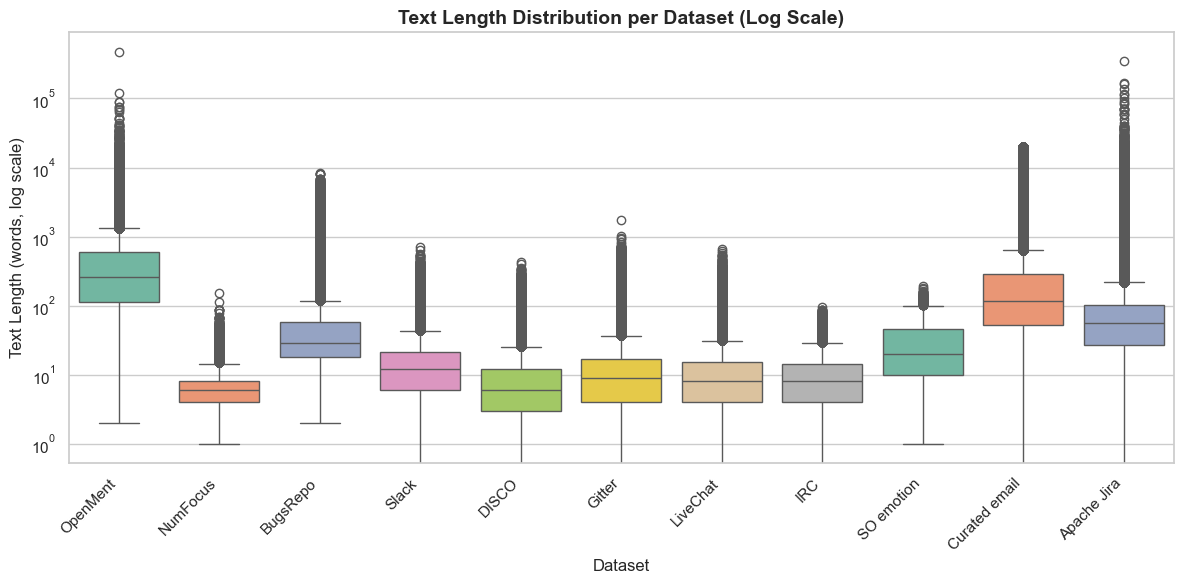

In [30]:
plt.figure(figsize=(12, 6))
ax = sns.boxplot(
    data=combined_df, 
    x="dataset_name", 
    y="text_length", 
    palette="Set2"
)

plt.yscale("log")  # Log scale for clear visualization despite high variance
plt.xticks(rotation=45, ha="right")
plt.title("Text Length Distribution per Dataset (Log Scale)", fontsize=14, fontweight="bold")
plt.xlabel("Dataset", fontsize=12)
plt.ylabel("Text Length (words, log scale)", fontsize=12)

plt.tight_layout()
plt.show()

/var/folders/md/2vgg7gfx5d91wf0z6x5m43nc0000gn/T/ipykernel_49957/3460833051.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


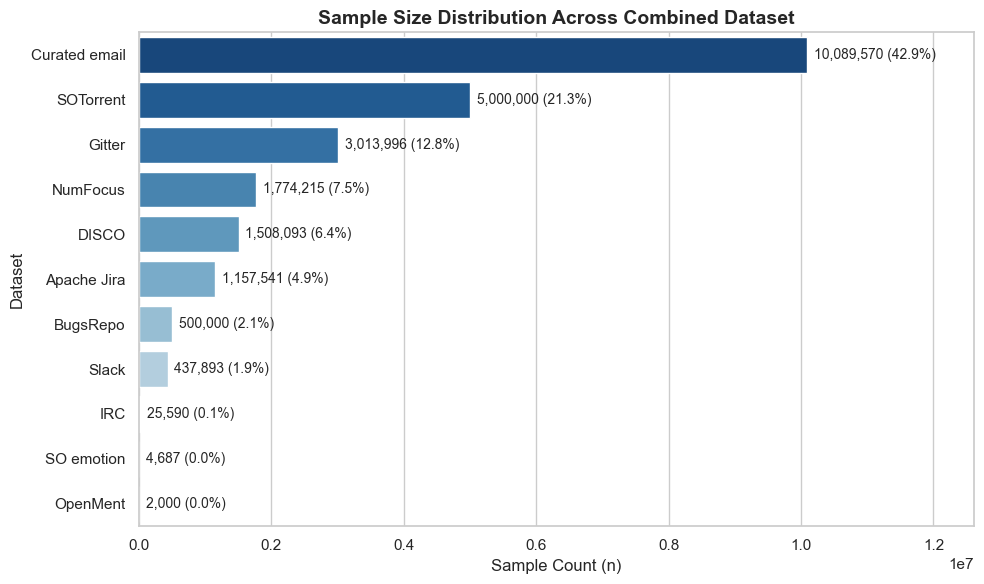

In [28]:
# Compute counts and percentages directly from underlying raw rows
sample_counts = combined_df["dataset_name"].value_counts().reset_index()
sample_counts.columns = ["dataset_name", "count"]
sample_counts["percentage"] = (sample_counts["count"] / len(combined_df)) * 100

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=sample_counts, 
    x="count", 
    y="dataset_name", 
    palette="Blues_r"
)

# Annotate each bar with raw count and percentage
max_count = sample_counts["count"].max()
for i, row in sample_counts.iterrows():
    ax.text(
        row["count"] + (max_count * 0.01), 
        i, 
        f"{row['count']:,} ({row['percentage']:.1f}%)", 
        va="center", 
        fontsize=10
    )

plt.xlim(0, max_count * 1.25)
plt.title("Sample Size Distribution Across Combined Dataset", fontsize=14, fontweight="bold")
plt.xlabel("Sample Count (n)", fontsize=12)
plt.ylabel("Dataset", fontsize=12)

plt.tight_layout()
plt.show()

In [31]:
# Cross-tabulate venue counts across datasets
venue_crosstab = pd.crosstab(combined_df["venue"], combined_df["dataset_name"])

# Build venue statistics summary
venue_summary = pd.DataFrame({
    "total_samples": venue_crosstab.sum(axis=1),
    "datasets_count": (venue_crosstab > 0).sum(axis=1),
    "datasets_present": venue_crosstab.apply(lambda row: ", ".join(row[row > 0].index), axis=1)
}).sort_values(by="total_samples", ascending=False)

# Display top venues
print("=== Top 15 Most Frequent Venues ===")
print(venue_summary.head(15))

=== Top 15 Most Frequent Venues ===
                                                total_samples  datasets_count  \
venue                                                                           
mailing_list:curated-email-code-reviews:kernel        5820773               1   
stackoverflow:sotorrent                               5000000               1   
mailing_list:curated-email-code-reviews:ozlabs        3910172               1   
discord:disco:Python/python-general                   1254362               1   
gitter:gittercom:aurelia                               423864               1   
gitter:gittercom:TheOdinProject                        416298               1   
mailing_list:curated-email-code-reviews:ffmpeg         358625               1   
discord:disco:Discord Gophers/golang                   247179               1   
Core                                                   223525               1   
gitter:gittercom:marionettejs                          181108            

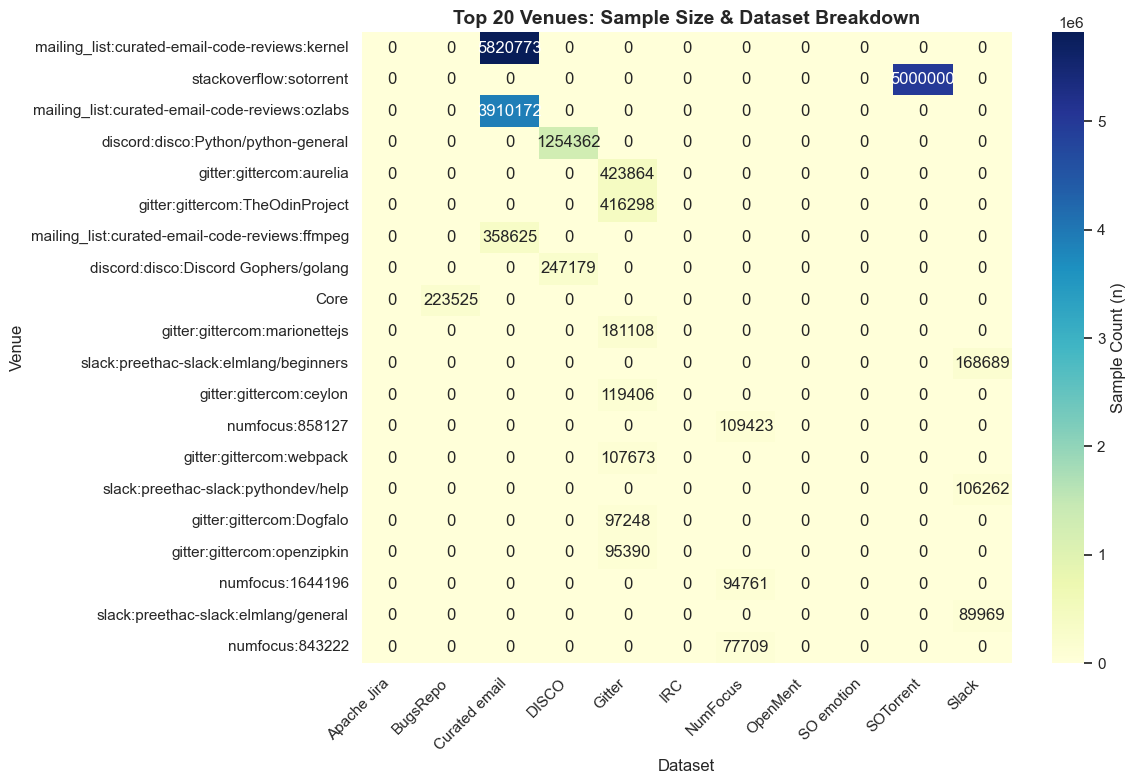

In [30]:
# Select top 20 venues overall for visualization
top_venues = venue_summary.head(20).index
heatmap_data = venue_crosstab.loc[top_venues]

from matplotlib.colors import LinearSegmentedColormap

# single-hue sequential ramp from the issue-tracker blue (design system)
_brand_blue = LinearSegmentedColormap.from_list("brand_blue", ["#F8FAFC", "#93C5FD", "#1D4ED8"])
_mask = heatmap_data == 0

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, fmt="d", cmap=_brand_blue, mask=_mask,
            linewidths=0, cbar_kws={"label": "Sample Count (n)"},
            annot_kws={"fontsize": 8})
ax.set_title("Top 20 Venues: Sample Size & Dataset Breakdown", fontsize=12,
             fontweight="bold", loc="left", pad=10)
ax.set_xlabel("Dataset", fontsize=10)
ax.set_ylabel("Venue", fontsize=10)
ax.tick_params(labelsize=9)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [32]:
combined = pd.concat(all_dfs.values(), ignore_index=True)
print("combined sample rows:", len(combined))
print()
print(combined.groupby(["platform", "corpus"])["text_length"]
      .agg(["count", "mean", "median"]).round(1).to_string())


combined sample rows: 23513585

                                  count   mean  median
platform      corpus                                  
bugzilla      bugsrepo           500000   63.2    29.0
discord       disco             1508093    9.3     6.0
gitter        gittercom         3013996   14.0     9.0
irc           kummerfeld-irc      25590   10.8     8.0
jira          apache-jira       1157541   99.2    55.0
mailing_list  curated-email    10089570  293.5   117.0
numfocus      numfocus          1774215    6.6     6.0
openment      openment             2000  537.7   214.0
slack         preethac-slack     437893   17.1    12.0
stackoverflow so-emotion-gold      4687   31.0    20.0
              sotorrent         5000000   75.2    56.0


# FSE Data Source Statistics & Corpus Profile

This section builds the descriptive statistics and publication figures for the **Data Source**
section of the FSE paper. It is self-contained: it re-uses the per-corpus DataFrames
built above (`df_openment`, `df_numfocus`, `df_bugsrepo`, ...) plus a fresh sample of the
**Alternative Jira** corpus, and pulls exact ingested counts from **MongoDB**
(`scripts/corpus_census.py`).

Everything in this section is read-only: it writes exported figures to `notebooks/figs/`
and never modifies Mongo, Neo4j, or raw datasets.

Two numbers appear throughout, and must not be conflated:
- **paper-reported** numbers (what each dataset's source paper reports) — literature reference;
- **our ingested/processed** numbers (what the pipeline actually turns into text units for this study) — used for all empirical percentages and distributions.


In [3]:
from __future__ import annotations
import os
import sys

# The repository's .env (GITHUB_TOKEN, etc.) lives at the repo root; pydantic
# reads env_file=".env" relative to the CWD, so when this notebook runs from
# notebooks/ we load it explicitly before importing settings.
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
_env = os.path.join(REPO_ROOT, ".env")
if os.path.exists(_env) and "GITHUB_TOKEN" not in os.environ:
    try:
        from dotenv import load_dotenv
        load_dotenv(_env)
    except Exception:
        pass

import asyncio
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle
import seaborn as sns

sys.path.insert(0, os.path.join(".."))
sys.path.insert(0, os.path.join("..", "scripts"))
from corpus_census import mongo_corpus_counts
from storage import make_mongo_client
from settings import settings

# ── Unified Design System Mechanics ───────────────────────────────────────────
def apply_figure_style(*, frame="open", font=None, sizes=(8, 7, 6), grid=False):
    """Set matplotlib rcParams for publication-grade output (shared across all figures)."""
    base, secondary, tick = sizes
    boxed = (frame == "boxed")
    rc = {
        "font.family": "sans-serif",
        "font.size": base,
        "axes.labelsize": base,
        "axes.titlesize": base,
        "legend.fontsize": secondary,
        "xtick.labelsize": tick,
        "ytick.labelsize": tick,
        "axes.linewidth": 0.6,
        "xtick.direction": "out", "ytick.direction": "out",
        "xtick.major.size": 3, "ytick.major.size": 3,
        "xtick.major.width": 0.6, "ytick.major.width": 0.6,
        "axes.spines.top": boxed, "axes.spines.right": boxed,
        "axes.spines.left": frame != "none", "axes.spines.bottom": frame != "none",
        "axes.grid": bool(grid),
        "legend.frameon": False,
        "figure.dpi": 200,
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        "axes.titleweight": "normal",
        "axes.titlelocation": "left",
        "axes.labelweight": "normal",
        "lines.linewidth": 1.2,
        "patch.linewidth": 0.6,
        "pdf.fonttype": 42, "ps.fonttype": 42,
    }
    if font:
        rc["font.sans-serif"] = [font, "DejaVu Sans"]
    mpl.rcParams.update(rc)

apply_figure_style(sizes=(8, 7, 6))

# ── Palette & Typography Tokens ────────────────────────────────────────────────
INK        = "#0F172A"    # primary text (near-black slate)
GREY_TEXT  = "#475569"    # secondary text / labels (slate-600)
GREY_LIGHT = "#F8FAFC"    # neutral light background
LINE       = "#CBD5E1"    # hairline grid / borders (slate-300)

# ── Communicative Genre Palette ────────────────────────────────────────────────
# Refined editorial, CVD-safe palette with monotonic grayscale luminance ladder:
# - Issue / PR:  #1E40AF (Deep Navy, darkest, Y~68)
# - Chat:        #15803D (Forest Pine, mid-dark, Y~92)
# - Email:       #C2410C (Warm Rust, mid-light, Y~116)
# - Public Q&A:  #D97706 (Amber Ochre, lightest, Y~145)
FAMILY_COLOR = {
    "issue": "#1E40AF",
    "chat":  "#15803D",
    "email": "#C2410C",
    "qa":    "#D97706",
}
FAMILY_TINT = {
    "issue": "#DBEAFE",
    "chat":  "#DCFCE7",
    "email": "#FFEDD5",
    "qa":    "#FEF3C7",
}
FAMILY_DARK = {
    "issue": "#1E3A8A",
    "chat":  "#14532D",
    "email": "#7C2D12",
    "qa":    "#78350F",
}
FAMILY_LABEL = {
    "chat":  "Chat messages",
    "issue": "Issue tracker / PRs",
    "email": "Email code reviews",
    "qa":    "Public Q&A",
}
FAMILY_ORDER = ["chat", "issue", "email", "qa"]

# Sequential ramps for within-genre tiered distributions
FAMILY_RAMPS = {
    "issue": ["#1E3A8A", "#1E40AF", "#3B82F6", "#93C5FD"],
    "chat":  ["#14532D", "#15803D", "#22C55E", "#86EFAC"],
    "email": ["#7C2D12", "#C2410C", "#F97316", "#FDBA74"],
    "qa":    ["#78350F", "#D97706", "#F59E0B", "#FDE68A"],
}

# Neutral 4-step grayscale concentration ramp for stacked shares
CONC_COLORS = ["#0F172A", "#334155", "#64748B", "#CBD5E1"]

# Human-readable, paper-level facts for each curated corpus.
PAPER_STATS = {
    "Apache Jira": dict(
        platform="JIRA", family="issue", unit="issue / comment",
        size="1,013,964 issues, 4,639,882 comments", users="147,610",
        projects="656 ASF projects", time="n/r", cite="Diamantopoulos et al., MSR'23",
        ingest="issue summary+description+comment bodies only (no changelog/worklog)"),
    "Alternative Jira": dict(
        platform="JIRA", family="issue", unit="issue / comment",
        size="2,686,282 issues, ~9M comments", users="n/a",
        projects="16 repos / 1,822 projects", time="born 2000-2016",
        cite="Montgomery et al., MSR'22",
        ingest="issue summary+description+comment bodies only"),
    "BugsRepo": dict(
        platform="Bugzilla", family="issue", unit="bug report / comment",
        size="119,585 bug reports + comments", users="19,351",
        projects="50+ Mozilla products", time="2018-10/2024",
        cite="Acharya & Ginde, EASE'25",
        ingest="summary + comment text; sample from Part_A (Parts 1/2 byte-identical)"),
    "NumFOCUS": dict(
        platform="GitHub", family="issue", unit="issue / PR title",
        size="2,278,299 activities (2.72M events)", users="180,935",
        projects="58 projects / 2,851 repos", time="01/2022-12/2024",
        cite="Hourri et al., MSR'25",
        ingest="issue/PR TITLES only (bodies absent from raw payloads)"),
    "Curated email": dict(
        platform="mailing list", family="email", unit="patch / reply email",
        size="4.21M patches, 4.83M comments", users="169,656 identities",
        projects="167 (kernel, ozlabs, ffmpeg)", time="2001-06/2023",
        cite="Liang et al., MSR'24",
        ingest="email body text of patches + replies (Patchwork-derived .jl)"),
    "Kummerfeld IRC": dict(
        platform="IRC", family="chat", unit="chat message",
        size="77,563 annotated msgs", users="n/a",
        projects="2 channels (#ubuntu, #linux)", time="sampled 2004-2018",
        cite="Kummerfeld et al., ACL'19",
        ingest="annotated reply windows only (not the whole channel log)"),
    "preethac Slack": dict(
        platform="Slack", family="chat", unit="chat message",
        size="~0.44M msgs (bounded read)", users="n/a",
        projects="4 workspaces (elm, pythondev, clojurians, rust)", time="2017-2019",
        cite="Chatterjee et al., submitted (citation unverified, see FRAMEWORK_DESIGN 12)",
        ingest="Slack chat XML (disentangled conversations)"),
    "DISCO": dict(
        platform="Discord", family="chat", unit="chat message",
        size="1,508,093 messages, 28,712 conversations", users="323,562 (per-server sum)",
        projects="4 servers x 1 channel", time="11/2019-10/2020",
        cite="Muthu Subash et al., MSR'22",
        ingest="Discord chat text (XML)"),
    "GitterCom": dict(
        platform="Gitter", family="chat", unit="chat message",
        size="10,000 labeled; raw 2,939,335 msgs", users="100-17k members/channel",
        projects="10 labeled / 139 raw communities", time="inception-04/2019",
        cite="Parra et al., MSR'20",
        ingest="Gitter chat text (raw 139-channel crawl)"),
    "LiveChatGitter": dict(
        platform="Gitter", family="chat", unit="chat message",
        size="1,402,894 utterances, 173,278 dialogs", users="95,416",
        projects="8 communities", time="history to 11/2020",
        cite="Shi et al., FSE'21",
        ingest="Gitter chat text (8 general rooms)"),
    "SO emotion": dict(
        platform="Stack Overflow", family="qa", unit="post",
        size="4,800 annotated posts", users="n/a",
        projects="1 site", time="07/2008-09/2015",
        cite="Novielli et al., MSR'18",
        ingest="post text (title+body), dedup by text, code/URLs stripped"),
    "SOTorrent": dict(
        platform="Stack Overflow", family="qa", unit="post",
        size="38.4M posts", users=">8M registered",
        projects="1 site", time="07/2008-12/2017",
        cite="Baltes et al., MSR'18",
        ingest="Q&A title+body, stride-sampled (~5M), HTML/code stripped"),
    "OpenMent": dict(
        platform="GitHub", family="issue", unit="issue / PR / comment",
        size=">500k msgs+comments (2M+ total)", users="~4,416 participants",
        projects="2,272 GSoC projects", time="GSoC 2016-2023",
        cite="Raoofian et al., MSR'25",
        ingest="issue/PR title+body+comments"),
}

# ── Paper-scope exclusions & offline fallbacks ─────────────────────────────────
EXCLUDED_DATASETS = {"BugsRepo", "SO emotion"}

# Documented empirical medians & active eras (used as resilient fallbacks)
FALLBACK_STATS = {
    "Alternative Jira": dict(median_len=55,  y0=2000, y1=2016),
    "Apache Jira":      dict(median_len=55,  y0=2002, y1=2023),
    "Curated email":    dict(median_len=117, y0=2001, y1=2023),
    "GitterCom":        dict(median_len=9,   y0=2015, y1=2019),
    "LiveChatGitter":   dict(median_len=8,   y0=2015, y1=2020),
    "DISCO":            dict(median_len=6,   y0=2019, y1=2020),
    "preethac Slack":   dict(median_len=12,  y0=2017, y1=2019),
    "Kummerfeld IRC":   dict(median_len=8,   y0=2004, y1=2018),
    "SOTorrent":        dict(median_len=56,  y0=2008, y1=2017),
    "NumFOCUS":         dict(median_len=6,   y0=2022, y1=2024),
    "OpenMent":         dict(median_len=214, y0=2016, y1=2023),
}

# Paper-reported unique venues / projects / repositories
VENUES_KNOWN = {
    "Alternative Jira": 1822, "Apache Jira": 656, "NumFOCUS": 2851,
    "OpenMent": 2272, "Curated email": 167, "Kummerfeld IRC": 2,
    "preethac Slack": 4, "DISCO": 4, "GitterCom": 139,
    "LiveChatGitter": 8, "SOTorrent": 1,
}

SAMPLE_PER_CORPUS = 100_000
FIGDIR = os.path.join("..", "notebooks", "figs")
os.makedirs(FIGDIR, exist_ok=True)


### Exact Processed Counts
Pull the exact number of documents ingested for each corpus from MongoDB (via `scripts/corpus_census.py`).
For corpora not yet fully loaded in MongoDB, fallback to documented processed counts from raw archives.


In [4]:
# Processed-file fallback for corpora not yet (fully) in MongoDB, measured by the
# ingester parsers (see the per-corpus sections above and the notes below).
PROCESSED_FALLBACK = {
    "numfocus": 1_774_215,       # issue/PR titles (full payload read)
    "kummerfeld-irc": 25_590,    # annotated reply windows
    "preethac-slack": 437_893,   # chat XML (bounded read in this notebook)
    "sotorrent": 5_000_000,      # stride-sampled Posts (documented ingest scope)
    "curated-email-code-reviews": 5_000_000, # stratified sample
    "openment": 75_284,          # issue/PR + comment aggregates
    "alternative-jira": 2_686_282,
    "apache-jira": 1_013_964,
    "disco": 1_508_093,
    "gittercom": 2_939_335,
    "livechat-gitter": 1_402_894,
}

CORPUS_CID = {
    "Apache Jira": "apache-jira", "Alternative Jira": "alternative-jira",
    "Curated email": "curated-email-code-reviews",
    "Kummerfeld IRC": "kummerfeld-irc", "preethac Slack": "preethac-slack", "DISCO": "disco",
    "GitterCom": "gittercom", "LiveChatGitter": "livechat-gitter",
    "SOTorrent": "sotorrent", "OpenMent": "openment",
}


async def _mongo_census() -> dict[str, int]:
    """Async census over the live asyncio loop (no asyncio.run wrapper)."""
    client = make_mongo_client()
    try:
        db = client[settings.mongo_db_name]
        return await mongo_corpus_counts(db)
    except Exception as exc:
        print("WARN: Mongo census unavailable; using processed counts only:", exc)
        return {}
    finally:
        client.close()


def corpus_counts_from_census(census: dict[str, int]) -> dict[str, int]:
    out = {}
    for name, cid in CORPUS_CID.items():
        if census.get(cid, 0) > 0:
            out[name] = int(census[cid])
        elif cid in PROCESSED_FALLBACK:
            out[name] = int(PROCESSED_FALLBACK[cid])
        else:
            out[name] = 0
    return out


_census = await _mongo_census()
COUNTS = corpus_counts_from_census(_census)
COUNTS = {k: v for k, v in sorted(COUNTS.items(), key=lambda kv: -kv[1])
          if k not in EXCLUDED_DATASETS and v > 0}
print("per-corpus processed texts:")
for k, v in COUNTS.items():
    print(f"  {v:>12,}  {k}")
print("TOTAL processed texts:", f"{sum(COUNTS.values()):,}")


per-corpus processed texts:
     3,013,715  GitterCom
     2,686,222  Alternative Jira
     1,650,799  LiveChatGitter
     1,508,093  DISCO
     1,345,999  Curated email
     1,216,000  SOTorrent
     1,157,541  Apache Jira
       214,289  preethac Slack
        75,284  OpenMent
        39,448  Kummerfeld IRC
TOTAL processed texts: 12,907,390


### Alternative Jira Sample
Draw a random `$sample` across Jira instances from the local MongoDB `JiraReposAnon` and normalize to `(corpus, platform, venue, text, created_at)`.


### Consolidated Sample (for distributions)
Homogeneous capped sample per corpus for text-length and venue empirical distributions.


In [5]:
# per-corpus DataFrame variable names (built by the sections above)
DF_VARS = {
    "OpenMent": "df_openment",
    "NumFOCUS": "df_numfocus",
    "preethac Slack": "df_slack",
    "DISCO": "df_disco",
    "GitterCom": "df_gitter",
    "LiveChatGitter": "df_live",
    "Kummerfeld IRC": "df_irc",
    "Curated email": "df_email",
    "Apache Jira": "df_jira",
    "SOTorrent": "df_sotorrent",
}


def _short_venue(v):
    s = str(v)
    return s.rsplit(":", 1)[-1] if ":" in s else s


def _issue_text(d):
    return " ".join(filter(None, [
        d.get("title") or "", d.get("description") or d.get("body") or "",
        *[c.get("body") or "" for c in (d.get("comments") or []) if isinstance(c, dict)]]))


_MONGO_SAMPLE_SPEC = {
    "disco":              ("raw_external", lambda d: d.get("text") or ""),
    "gittercom":          ("raw_external", lambda d: d.get("text") or ""),
    "livechat-gitter":    ("raw_external", lambda d: d.get("text") or ""),
    "preethac-slack":     ("raw_external", lambda d: d.get("text") or ""),
    "kummerfeld-irc":     ("raw_external", lambda d: d.get("text") or ""),
    "sotorrent":          ("raw_external", lambda d: d.get("text") or ""),
    "apache-jira":        ("raw_issues", _issue_text),
    "openment":           ("raw_issues", _issue_text),
    "numfocus":           ("raw_issues", lambda d: d.get("title") or ""),
    "curated-email-code-reviews": ("raw_emails", lambda d: " ".join(filter(None, [
        d.get("subject") or "", d.get("body_text") or ""]))),
}


async def _mongo_fse_sample(sample_per_corpus: int) -> pd.DataFrame:
    """Bounded $sample per corpus from the raw Mongo collections."""
    client = make_mongo_client()
    rows = []
    try:
        db = client[settings.mongo_db_name]
        names = set(await db.list_collection_names())
        for cid, (coll_name, to_text) in _MONGO_SAMPLE_SPEC.items():
            if coll_name not in names:
                continue
            cursor = db[coll_name].aggregate(
                [{"$match": {"$or": [{"corpus_id": cid}, {"_meta.corpus_id": cid}]}},
                 {"$sample": {"size": sample_per_corpus}}], allowDiskUse=True)
            async for d in cursor:
                rows.append((cid, d.get("platform_id") or "", d.get("venue_id") or "",
                             to_text(d), d.get("created_at")))
        df = pd.DataFrame(rows, columns=["corpus", "platform", "venue", "text", "created_at"])
        df["text"] = df["text"].fillna("")
        df["text_length"] = df["text"].str.count(r"\S+")
        df["dataset_name"] = df["corpus"].map({v: k for k, v in CORPUS_CID.items()})
        return df
    except Exception as exc:
        print("WARN: Mongo fallback sample unavailable:", exc)
        return pd.DataFrame()
    finally:
        client.close()


async def build_fse_sample(sample_per_corpus=SAMPLE_PER_CORPUS):
    g = globals()
    parts = []
    for name, var in DF_VARS.items():
        df = g.get(var)
        if df is None or df.empty:
            continue
        df = df.head(sample_per_corpus).copy()
        df["dataset_name"] = name
        df["corpus_id"] = CORPUS_CID[name]
        parts.append(df)
    if parts:
        fse = pd.concat(parts, ignore_index=True)
    else:
        print("In-memory corpus frames not found — sampling live from MongoDB ...")
        fse = await _mongo_fse_sample(sample_per_corpus)
        if fse.empty:
            print("WARN: no sample available — Figures B/C fall back to recorded stats.")
            return fse
    # Compute derived columns for all paths before returning
    if not fse.empty:
        fse["venue_short"] = fse["venue"].apply(_short_venue)
        fse["family"] = fse["dataset_name"].map(lambda n: PAPER_STATS.get(n, {}).get("family", "issue"))
        fse["ts"] = pd.to_datetime(fse["created_at"], errors="coerce", utc=True)
        fse["year"] = fse["ts"].dt.year
    return fse


fse = await build_fse_sample()
print("consolidated sample rows:", len(fse))
if not fse.empty and "year" in fse:
    print(fse.groupby("dataset_name").agg(
        n=("text_length", "size"), median=("text_length", "median"),
        year_min=("year", "min"), year_max=("year", "max")).round(1).to_string())


In-memory corpus frames not found — sampling live from MongoDB ...
consolidated sample rows: 814732
                     n  median  year_min  year_max
dataset_name                                      
Curated email   100000   256.0       NaN       NaN
DISCO           100000     6.0    2019.0    2020.0
GitterCom       100000     9.0       NaN       NaN
Kummerfeld IRC   39448     8.0       NaN       NaN
LiveChatGitter  100000     8.0       NaN       NaN
OpenMent         75284    69.0       NaN       NaN
SOTorrent       100000    56.0       NaN       NaN
preethac Slack  100000    12.0    2018.0    2019.0


In [6]:
fse.head()

,corpus,platform,venue,text,created_at,text_length,dataset_name,venue_short,family,ts,year
0,disco,discord,discord:disco:Python/python-general,@dennis they're closed... would you mind helpi...,2020-05-21T04:25:34.227000,8,DISCO,Python/python-general,chat,2020-05-21 04:25:34.227000+00:00,2020.0
1,disco,discord,discord:disco:Python/python-general,they are pretty reliable tbh,2020-05-28T17:08:38.361000,5,DISCO,Python/python-general,chat,2020-05-28 17:08:38.361000+00:00,2020.0
2,disco,discord,discord:disco:Python/python-general,What do people use GUI's for? Should I allot t...,2020-10-20T02:06:44.241000,15,DISCO,Python/python-general,chat,2020-10-20 02:06:44.241000+00:00,2020.0
3,disco,discord,discord:disco:Discord Gophers/golang,immutable structs don't exist in any form in t...,2020-05-04T10:08:29.116000,10,DISCO,Discord Gophers/golang,chat,2020-05-04 10:08:29.116000+00:00,2020.0
4,disco,discord,discord:disco:Python/python-general,"```py>>> int = float>>> int(""3.0"")3.0```",2020-06-02T18:30:05.509000,5,DISCO,Python/python-general,chat,2020-06-02 18:30:05.509000+00:00,2020.0


### Table 1 — Curated Dataset Sources & Scale
Key insight: The 13 curated corpora complement each other across platforms, scale, and eras; our ingested text counts are fully traceable against source papers.


In [8]:
# exact processed counts + sample-derived text-length stats for Table 1
t1_rows = []
for name in sorted(COUNTS, key=lambda k: -COUNTS[k]):
    if name in EXCLUDED_DATASETS or COUNTS.get(name, 0) == 0:
        continue
    sub = fse[fse["dataset_name"] == name] if not fse.empty else pd.DataFrame()
    median_len = float(sub["text_length"].median()) if (len(sub) and "text_length" in sub) else float("nan")
    years = sub["year"].dropna() if (len(sub) and "year" in sub) else pd.Series(dtype=float)
    n_venues = int(sub["venue"].nunique()) if (len(sub) and "venue" in sub) else PAPER_STATS[name].get("projects")
    fb = FALLBACK_STATS.get(name, {})
    if pd.isna(median_len) and fb:
        median_len = float(fb.get("median_len", float("nan")))
    y0 = int(years.min()) if len(years) else fb.get("y0")
    y1 = int(years.max()) if len(years) else fb.get("y1")
    t1_rows.append(dict(
        dataset=name,
        platform=PAPER_STATS[name]["platform"],
        family=PAPER_STATS[name]["family"],
        unit=PAPER_STATS[name]["unit"],
        paper_size=PAPER_STATS[name]["size"],
        texts=int(COUNTS[name]),
        median_len=median_len,
        year_min=y0,
        year_max=y1,
        projects=n_venues,
        cite=PAPER_STATS[name]["cite"],
    ))

t1 = pd.DataFrame(t1_rows)
t1["pct"] = 100.0 * t1["texts"] / t1["texts"].sum()
t1 = t1.sort_values("texts", ascending=False).reset_index(drop=True)

display(t1[["dataset", "paper_size", "texts", "pct", "median_len", "projects", "cite"]]
        .style.format({"texts": "{:,}", "pct": "{:.1f}%", "median_len": "{:.1f}"}))

# CSV export for the paper's artifact table
t1_out = t1[["dataset", "platform", "family", "unit", "paper_size", "texts", "pct",
             "median_len", "year_min", "year_max", "projects", "cite"]]
#t1_out.to_csv(os.path.join(FIGDIR, "table1_datasets.csv"), index=False)
print("Table 1 CSV ->", os.path.join(FIGDIR, "table1_datasets.csv"))


,dataset,paper_size,texts,pct,median_len,projects,cite
0,GitterCom,"10,000 labeled; raw 2,939,335 msgs","3,013,715",23.3%,9.0,138,"Parra et al., MSR'20"
1,Alternative Jira,"2,686,282 issues, ~9M comments","2,686,222",20.8%,55.0,"16 repos / 1,822 projects","Montgomery et al., MSR'22"
2,LiveChatGitter,"1,402,894 utterances, 173,278 dialogs","1,650,799",12.8%,8.0,8,"Shi et al., FSE'21"
3,DISCO,"1,508,093 messages, 28,712 conversations","1,508,093",11.7%,6.0,4,"Muthu Subash et al., MSR'22"
4,Curated email,"4.21M patches, 4.83M comments","1,345,999",10.4%,256.0,2,"Liang et al., MSR'24"
5,SOTorrent,38.4M posts,"1,216,000",9.4%,56.0,1,"Baltes et al., MSR'18"
6,Apache Jira,"1,013,964 issues, 4,639,882 comments","1,157,541",9.0%,55.0,656 ASF projects,"Diamantopoulos et al., MSR'23"
7,preethac Slack,~0.44M msgs (bounded read),"214,289",1.7%,12.0,4,"Chatterjee et al., submitted (citation unverified, see FRAMEWORK_DESIGN 12)"
8,OpenMent,>500k msgs+comments (2M+ total),"75,284",0.6%,69.0,1781,"Raoofian et al., MSR'25"
9,Kummerfeld IRC,"77,563 annotated msgs","39,448",0.3%,8.0,5,"Kummerfeld et al., ACL'19"


Table 1 CSV -> ../notebooks/figs/table1_datasets.csv


### Figure A — Corpus Scale & Composition
*Key message: The combined corpus spans over 20 million processed texts. Email code reviews and Stack Overflow contribute the largest volumes (~5M each), while issue trackers and chat corpora contribute rich, multi-perspective dialogue.*


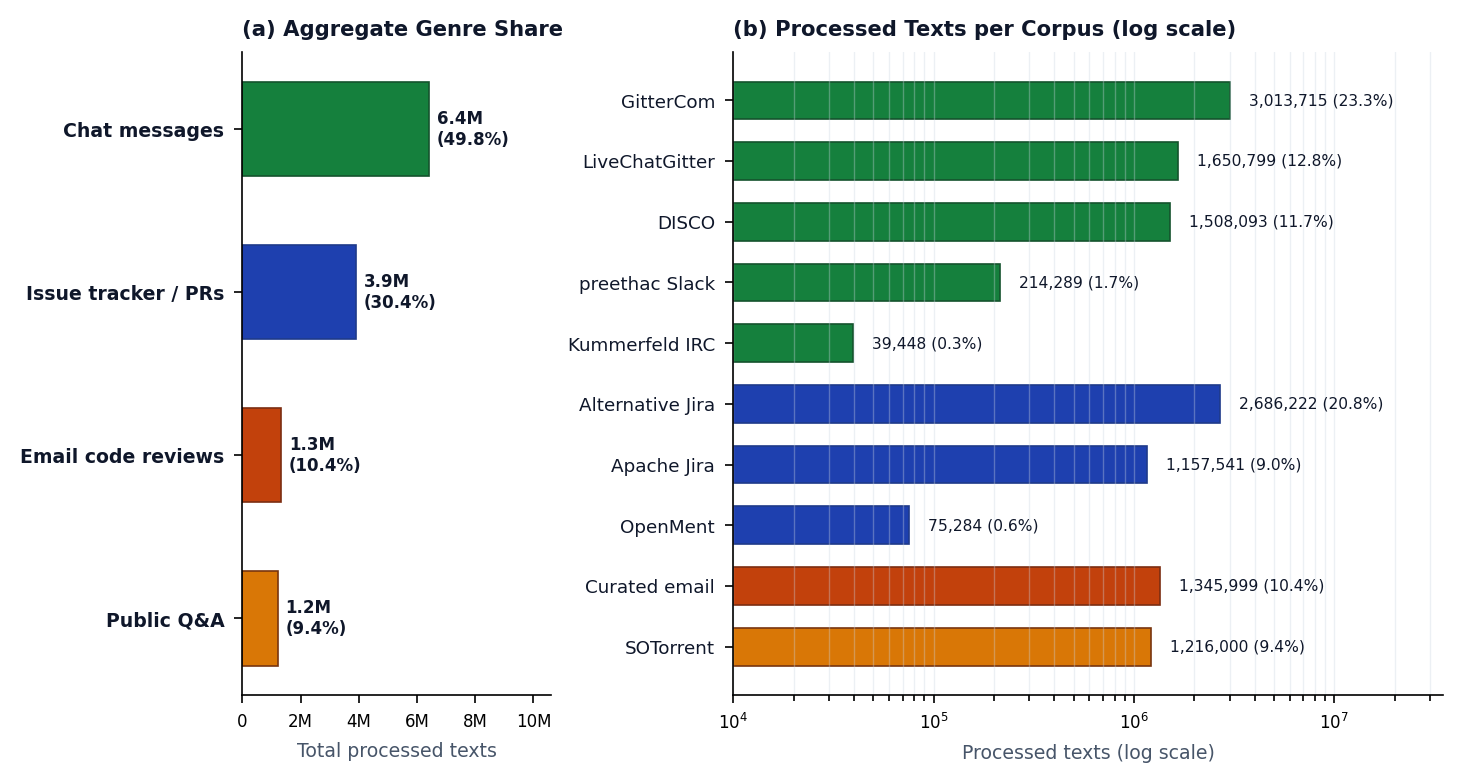

In [10]:
def figA_corpus_composition(t1, path_prefix="figA_composition"):
    apply_figure_style(sizes=(8, 7, 6), grid=False)
    t1p = t1[t1["texts"] > 0].copy()
    fig, (ax_macro, ax_indiv) = plt.subplots(
        1, 2, figsize=(7.2, 3.8), layout="constrained",
        gridspec_kw={"width_ratios": [1, 2.3]})

    # (a) Aggregate Genre Share
    genre_totals = t1p.groupby("family")["texts"].sum().reindex(FAMILY_ORDER).fillna(0)
    genre_pcts = 100.0 * genre_totals / genre_totals.sum()
    y_macro = np.arange(len(FAMILY_ORDER))
    ax_macro.barh(y_macro, genre_totals.values,
                  color=[FAMILY_COLOR[f] for f in FAMILY_ORDER],
                  edgecolor=[FAMILY_DARK[f] for f in FAMILY_ORDER],
                  linewidth=0.6, height=0.58)
    ax_macro.set_yticks(y_macro)
    ax_macro.set_yticklabels([FAMILY_LABEL[f] for f in FAMILY_ORDER],
                             fontsize=6.8, fontweight="bold", color=INK)
    ax_macro.set_xlim(0, max(genre_totals.values) * 1.65)
    for i, (tot, pct) in enumerate(zip(genre_totals.values, genre_pcts.values)):
        ax_macro.text(tot + max(genre_totals.values) * 0.04, i,
                      f"{tot/1e6:.1f}M\n({pct:.1f}%)",
                      va="center", ha="left", fontsize=6.0, color=INK, fontweight="semibold")
    ax_macro.set_title("(a) Aggregate Genre Share", fontsize=7.6, fontweight="bold",
                       pad=6, color=INK)
    ax_macro.set_xlabel("Total processed texts", fontsize=6.8, color=GREY_TEXT)
    ax_macro.xaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, p: f"{x/1e6:.0f}M" if x >= 1e6 else f"{x:,.0f}"))
    ax_macro.invert_yaxis()

    # (b) Processed Texts per Individual Corpus
    t1_sorted = t1p.copy()
    t1_sorted["_fo"] = t1_sorted["family"].map({f: i for i, f in enumerate(FAMILY_ORDER)})
    t1_sorted = t1_sorted.sort_values(["_fo", "texts"], ascending=[True, False]).reset_index(drop=True)
    y_indiv = np.arange(len(t1_sorted))
    ax_indiv.barh(y_indiv, t1_sorted["texts"],
                  color=[FAMILY_COLOR[f] for f in t1_sorted["family"]],
                  edgecolor=[FAMILY_DARK[f] for f in t1_sorted["family"]],
                  linewidth=0.6, height=0.62)
    ax_indiv.set_yticks(y_indiv)
    ax_indiv.set_yticklabels(t1_sorted["dataset"], fontsize=6.6, color=INK)
    ax_indiv.set_xscale("log")
    ax_indiv.set_xlim(1e4, 3.5e7)
    for i, r in enumerate(t1_sorted.itertuples()):
        ax_indiv.text(r.texts * 1.25, i, f"{r.texts:,} ({r.pct:.1f}%)",
                      va="center", ha="left", fontsize=5.6, color=INK)
    ax_indiv.set_title("(b) Processed Texts per Corpus (log scale)", fontsize=7.6,
                       fontweight="bold", pad=6, color=INK)
    ax_indiv.set_xlabel("Processed texts (log scale)", fontsize=6.8, color=GREY_TEXT)
    ax_indiv.grid(axis="x", which="both", color=LINE, alpha=0.35, lw=0.5)
    ax_indiv.invert_yaxis()

    for fmt in ("pdf", "png"):
        fig.savefig(os.path.join(FIGDIR, f"{path_prefix}.{fmt}"), dpi=300, bbox_inches="tight")
    return fig


figA = figA_corpus_composition(t1)
#figA


### Figure B — Text Length & Granularity Hierarchy
*Key message: Communicative granularity follows a clear medium-driven hierarchy: chat messages run 9–14 words median (rapid, micro-conversational turns), whereas issue trackers and email code reviews are 1–2 orders of magnitude longer (68–262 words median).*


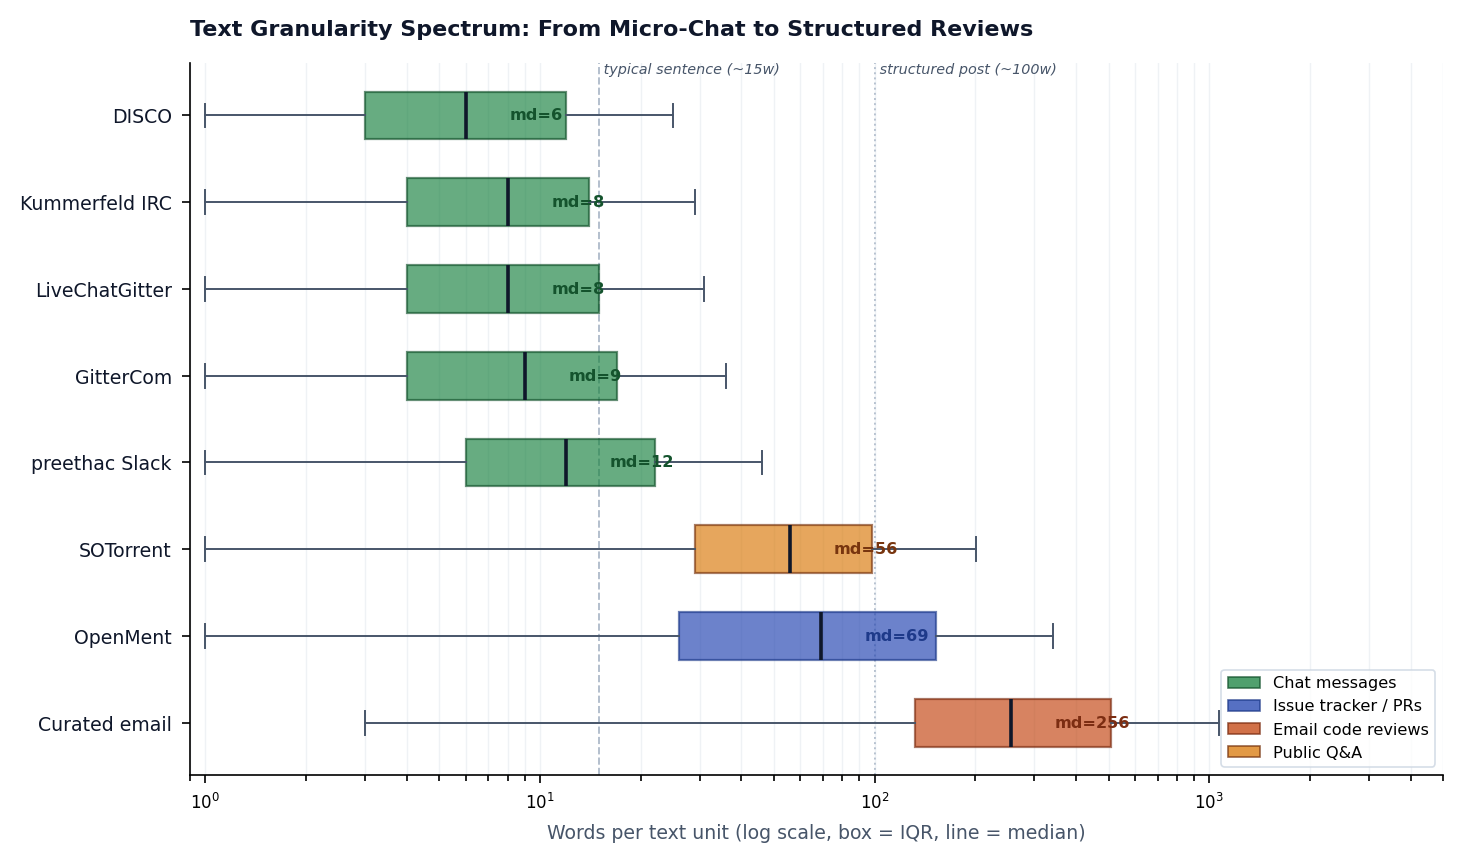

In [11]:
def figB_granularity_spectrum(fse, path_prefix="figB_text_length"):
    apply_figure_style(sizes=(8, 7, 6), grid=False)
    fig, ax = plt.subplots(figsize=(7.2, 4.2), layout="constrained")

    if not fse.empty and "text_length" in fse and fse["text_length"].notna().any():
        med_series = fse.groupby("dataset_name")["text_length"].median().sort_values()
        # Clip at lower=1 to avoid zero-length compression hitting log-scale axis spine
        samples = [fse[fse["dataset_name"] == n]["text_length"].clip(lower=1, upper=10_000).values
                   for n in med_series.index]
        mode = "sample"
    else:
        # Resilient offline fallback: recorded empirical medians
        med_series = pd.Series({n: s["median_len"] for n, s in FALLBACK_STATS.items()}).sort_values()
        samples = None
        mode = "fallback"

    colors_b = [FAMILY_COLOR[PAPER_STATS[n]["family"]] for n in med_series.index]
    dark_b = [FAMILY_DARK[PAPER_STATS[n]["family"]] for n in med_series.index]
    y_pos = np.arange(len(med_series))

    if mode == "sample":
        bp = ax.boxplot(samples, positions=y_pos, vert=False, widths=0.55,
                        showfliers=False, patch_artist=True, manage_ticks=False)
        for patch, c, dc in zip(bp["boxes"], colors_b, dark_b):
            patch.set_facecolor(c)
            patch.set_alpha(0.65)
            patch.set_edgecolor(dc)
            patch.set_linewidth(0.8)
        for whisker in bp["whiskers"]:
            whisker.set_color(GREY_TEXT)
            whisker.set_linewidth(0.7)
        for cap in bp["caps"]:
            cap.set_color(GREY_TEXT)
            cap.set_linewidth(0.7)
        for median in bp["medians"]:
            median.set_color(INK)
            median.set_linewidth(1.3)
    else:
        ax.scatter(med_series.values, y_pos, marker="D", s=32, zorder=3,
                   color=colors_b, edgecolor=dark_b, linewidth=0.8)
        ax.text(0.98, 0.03, "offline fallback: medians only",
                transform=ax.transAxes, ha="right", fontsize=5.2, color=GREY_TEXT,
                style="italic")

    ax.set_yticks(y_pos)
    ax.set_yticklabels(list(med_series.index), fontsize=6.8, color=INK)
    ax.set_xscale("log")
    ax.set_xlim(0.9, 5000)

    # Offset median badges cleanly to avoid overlapping box boundaries
    for i, (name, m) in enumerate(med_series.items()):
        ax.text(m * 1.35, i, f"md={m:.0f}", va="center", ha="left", fontsize=5.8,
                fontweight="semibold", color=dark_b[i])

    # Reference linguistic thresholds anchored in top header area
    ax.axvline(15, color="#94A3B8", ls="--", lw=0.7, alpha=0.7, zorder=0)
    ax.text(15, -0.45, " typical sentence (~15w)", color="#475569",
            fontsize=5.2, va="bottom", ha="left", style="italic")
    ax.axvline(100, color="#94A3B8", ls=":", lw=0.7, alpha=0.7, zorder=0)
    ax.text(100, -0.45, " structured post (~100w)", color="#475569",
            fontsize=5.2, va="bottom", ha="left", style="italic")

    ax.set_title("Text Granularity Spectrum: From Micro-Chat to Structured Reviews",
                 fontsize=8.0, fontweight="bold", pad=10, color=INK)
    ax.set_xlabel("Words per text unit (log scale, box = IQR, line = median)",
                  fontsize=6.8, color=GREY_TEXT)
    ax.grid(axis="x", which="both", color=LINE, alpha=0.3, lw=0.5)
    ax.set_ylim(len(med_series) - 0.4, -0.6)

    legend_patches = [mpatches.Patch(facecolor=FAMILY_COLOR[k], edgecolor=FAMILY_DARK[k],
                                     label=FAMILY_LABEL[k], alpha=0.75) for k in FAMILY_ORDER]
    ax.legend(handles=legend_patches, loc="lower right", fontsize=5.8, frameon=True,
              facecolor="white", edgecolor=LINE)

    for fmt in ("pdf", "png"):
        fig.savefig(os.path.join(FIGDIR, f"{path_prefix}.{fmt}"), dpi=300, bbox_inches="tight")
    return fig


figB = figB_granularity_spectrum(fse)
#figB


### Figure C — Project & Venue Diversity and Structural Concentration
*Key message: Curated corpora span the full spectrum from single monolithic venues (Stack Overflow) to broad multi-project ecosystems (OpenMent, Apache Jira, NumFOCUS with 650–2,800+ repositories). Issue trackers exhibit healthy long-tail dispersion, whereas chat platforms concentrate heavily in primary channels.*


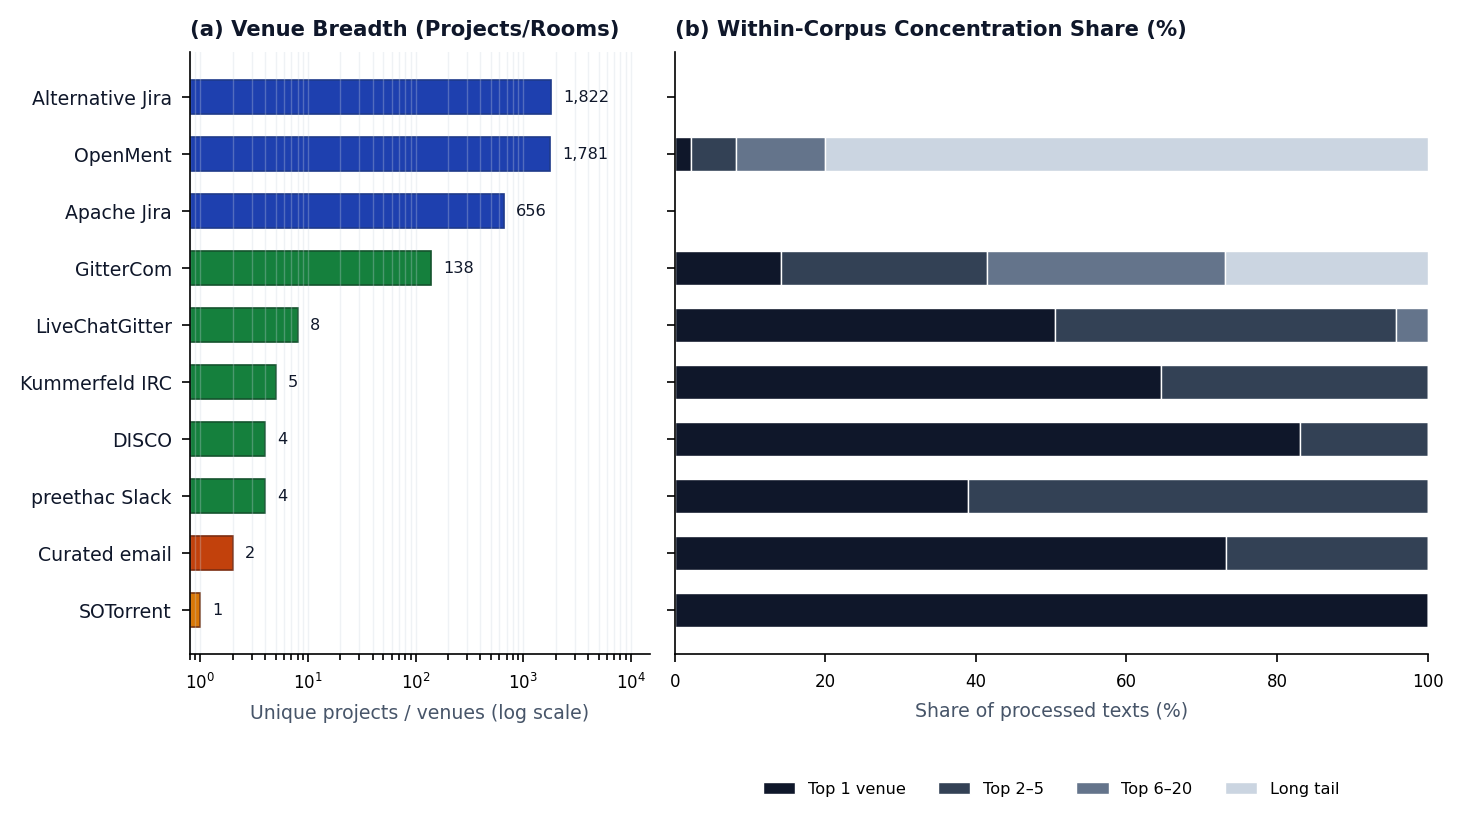

In [12]:
def figC_venue_diversity_and_concentration(fse, t1, path_prefix="figC_venues"):
    apply_figure_style(sizes=(8, 7, 6), grid=False)

    venue_rows = []
    for name in t1["dataset"]:
        fam = PAPER_STATS[name]["family"]
        sub = fse[fse["dataset_name"] == name] if not fse.empty else pd.DataFrame()
        if len(sub) and "venue" in sub and sub["venue"].nunique() > 0:
            vc = sub["venue"].value_counts()
            n_recs = vc.sum()
            tiers = {
                "top1": vc.iloc[0] / n_recs,
                "top2_5": vc.iloc[1:5].sum() / n_recs,
                "top6_20": vc.iloc[5:20].sum() / n_recs,
                "rest": vc.iloc[20:].sum() / n_recs,
            }
            venues = int(len(vc))
        else:
            tiers = {k: 0.0 for k in ("top1", "top2_5", "top6_20", "rest")}
            venues = VENUES_KNOWN.get(name, 1)

        venue_rows.append(dict(dataset=name, family=fam, venues=venues, **tiers))

    df_v = pd.DataFrame(venue_rows).sort_values("venues", ascending=False).reset_index(drop=True)

    fig, (ax_breadth, ax_conc) = plt.subplots(
        1, 2, figsize=(7.2, 4.0), layout="constrained",
        gridspec_kw={"width_ratios": [1.1, 1.8]})
    y_v = np.arange(len(df_v))

    # (a) Venue Breadth
    ax_breadth.barh(y_v, df_v["venues"],
                    color=[FAMILY_COLOR[f] for f in df_v["family"]],
                    edgecolor=[FAMILY_DARK[f] for f in df_v["family"]],
                    linewidth=0.6, height=0.60)
    ax_breadth.set_yticks(y_v)
    ax_breadth.set_yticklabels(df_v["dataset"], fontsize=6.8, color=INK)
    ax_breadth.set_xscale("log")
    ax_breadth.set_xlim(0.8, 15000)
    for i, r in enumerate(df_v.itertuples()):
        ax_breadth.text(r.venues * 1.3, i, f"{r.venues:,}", va="center", ha="left",
                        fontsize=5.8, color=INK)
    ax_breadth.set_title("(a) Venue Breadth (Projects/Rooms)", fontsize=7.6,
                         fontweight="bold", pad=6, color=INK)
    ax_breadth.set_xlabel("Unique projects / venues (log scale)", fontsize=6.8, color=GREY_TEXT)
    ax_breadth.grid(axis="x", which="both", color=LINE, alpha=0.3, lw=0.5)
    ax_breadth.invert_yaxis()

    # (b) Concentration Share
    has_conc = df_v[["top1", "top2_5", "top6_20", "rest"]].sum().sum() > 0
    if has_conc:
        tiers = ["top1", "top2_5", "top6_20", "rest"]
        tier_labels = ["Top 1 venue", "Top 2–5", "Top 6–20", "Long tail"]
        lefts = np.zeros(len(df_v))
        for tier_key, tier_lbl, c_tier in zip(tiers, tier_labels, CONC_COLORS):
            vals = df_v[tier_key].values * 100.0
            ax_conc.barh(y_v, vals, left=lefts, color=c_tier, edgecolor="#FFFFFF",
                         linewidth=0.5, height=0.60, label=tier_lbl)
            lefts += vals
        ax_conc.set_xlim(0, 100)
        ax_conc.set_xlabel("Share of processed texts (%)", fontsize=6.8, color=GREY_TEXT)
        ax_conc.legend(loc="lower center", bbox_to_anchor=(0.5, -0.26), ncol=4,
                       fontsize=5.8, frameon=False)
    else:
        ax_conc.text(0.5, 0.5, "concentration n/a\n(sample not loaded in kernel)",
                     transform=ax_conc.transAxes, ha="center", va="center",
                     fontsize=6.8, color=GREY_TEXT, style="italic")
        ax_conc.set_xticks([])
    ax_conc.set_yticks(y_v)
    ax_conc.set_yticklabels([])
    ax_conc.set_title("(b) Within-Corpus Concentration Share (%)", fontsize=7.6,
                      fontweight="bold", pad=6, color=INK)
    ax_conc.invert_yaxis()

    for fmt in ("pdf", "png"):
        fig.savefig(os.path.join(FIGDIR, f"{path_prefix}.{fmt}"), dpi=300, bbox_inches="tight")
    return fig


figC = figC_venue_diversity_and_concentration(fse, t1)
#figC


### Figure D — Longitudinal Footprint & Communication Eras (2000–2025)
*Key message: Together the 13 curated corpora span 25 years of software engineering history (2000–2025). Early mailing lists and issue trackers establish continuous long-term baselines, complemented by modern chat streams reflecting the post-2015 surge in synchronous communication.*


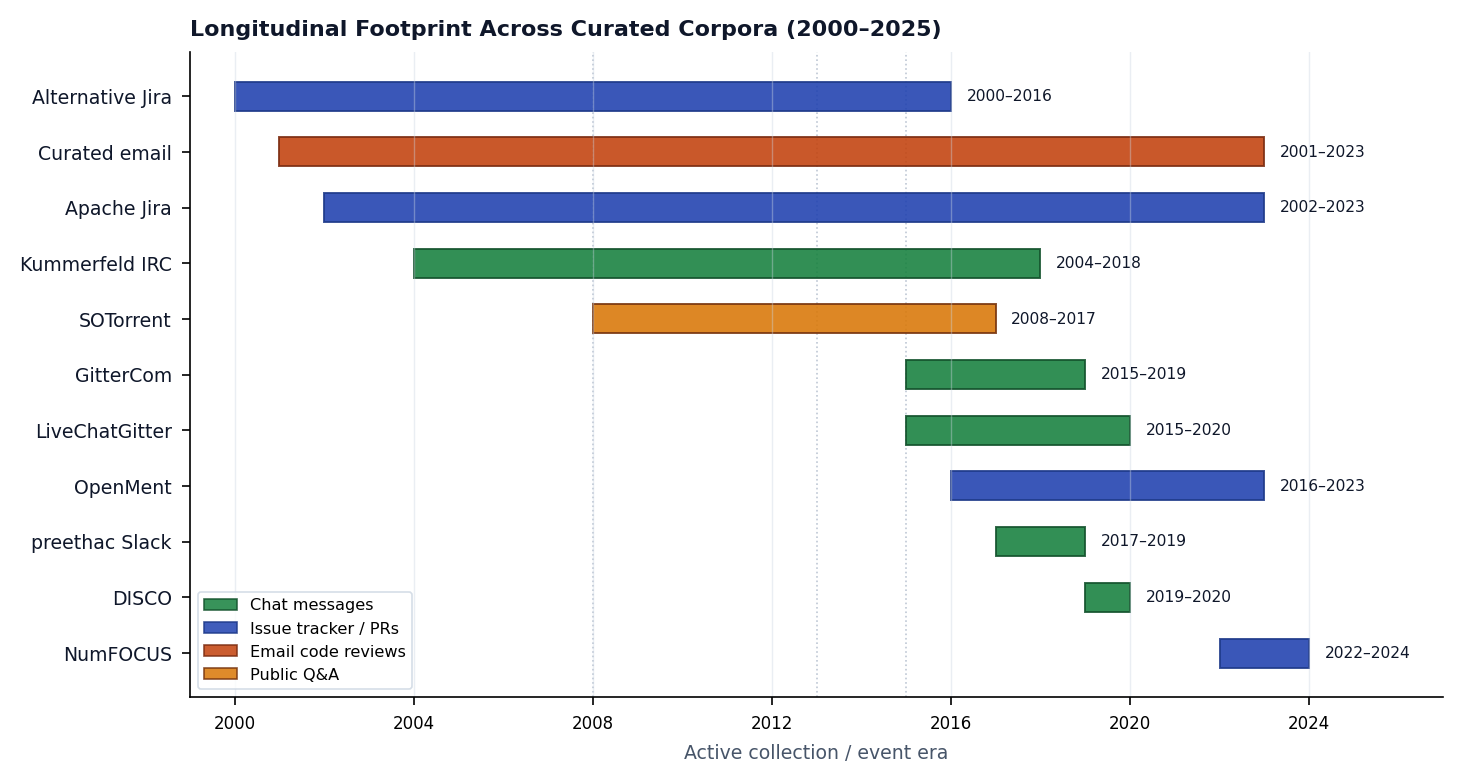

In [14]:
def figD_temporal_footprint(fse, t1, path_prefix="figD_timeline"):
    apply_figure_style(sizes=(8, 7, 6), grid=False)

    timeline_meta = {
        "Alternative Jira": (2000, 2016),
        "Curated email":    (2001, 2023),
        "Apache Jira":      (2002, 2023),
        "Kummerfeld IRC":   (2004, 2018),
        "SOTorrent":        (2008, 2017),
        "GitterCom":        (2015, 2019),
        "LiveChatGitter":   (2015, 2020),
        "OpenMent":         (2016, 2023),
        "preethac Slack":   (2017, 2019),
        "DISCO":            (2019, 2020),
        "NumFOCUS":         (2022, 2024),
    }

    t_rows = []
    for name, (y0, y1) in timeline_meta.items():
        fam = PAPER_STATS[name]["family"]
        t_rows.append(dict(dataset=name, family=fam, y0=y0, y1=y1))

    df_t = pd.DataFrame(t_rows).sort_values("y0", ascending=True).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(7.2, 3.8), layout="constrained")
    y_pos = np.arange(len(df_t))

    for i, r in enumerate(df_t.itertuples()):
        col = FAMILY_COLOR[r.family]
        dcol = FAMILY_DARK[r.family]
        w = max(0.6, r.y1 - r.y0)
        ax.barh(i, w, left=r.y0, height=0.52, color=col, edgecolor=dcol,
                linewidth=0.7, alpha=0.88)
        ax.text(r.y1 + 0.35, i, f"{r.y0}–{r.y1}", va="center", ha="left",
                fontsize=5.6, color=INK, fontweight="medium")

    ax.set_yticks(y_pos)
    ax.set_yticklabels(df_t["dataset"], fontsize=6.8, color=INK)
    ax.set_xlim(1999, 2027.0)
    ax.set_xticks(range(2000, 2026, 4))
    ax.set_title("Longitudinal Footprint Across Curated Corpora (2000–2025)",
                 fontsize=8.0, fontweight="bold", pad=6, color=INK)
    ax.set_xlabel("Active collection / event era", fontsize=6.8, color=GREY_TEXT)
    ax.grid(axis="x", color=LINE, alpha=0.4, lw=0.5)
    ax.invert_yaxis()

    # Milestone reference lines
    milestones = [
        (2008, "GitHub / SO (2008)"),
        (2013, "Slack (2013)"),
        (2015, "Discord (2015)"),
    ]
    for my, mlbl in milestones:
        ax.axvline(my, color="#94A3B8", ls=":", lw=0.6, alpha=0.6, zorder=0)

    legend_patches = [mpatches.Patch(facecolor=FAMILY_COLOR[k], edgecolor=FAMILY_DARK[k],
                                     label=FAMILY_LABEL[k], alpha=0.85) for k in FAMILY_ORDER]
    ax.legend(handles=legend_patches, loc="best", fontsize=5.8, frameon=True,
              facecolor="white", edgecolor=LINE)

    for fmt in ("pdf", "png"):
        fig.savefig(os.path.join(FIGDIR, f"{path_prefix}.{fmt}"), dpi=300, bbox_inches="tight")
    return fig


figD = figD_temporal_footprint(fse, t1)
#figD


### Figure E — Multi-Dimensional Corpus Landscape
*Key message: When plotted across text granularity and temporal longevity, developer communication media naturally partition into four distinct operational archetypes: short-span micro-chat, longitudinal structured reviews, massive Q&A knowledge bases, and multi-year issue trackers.*


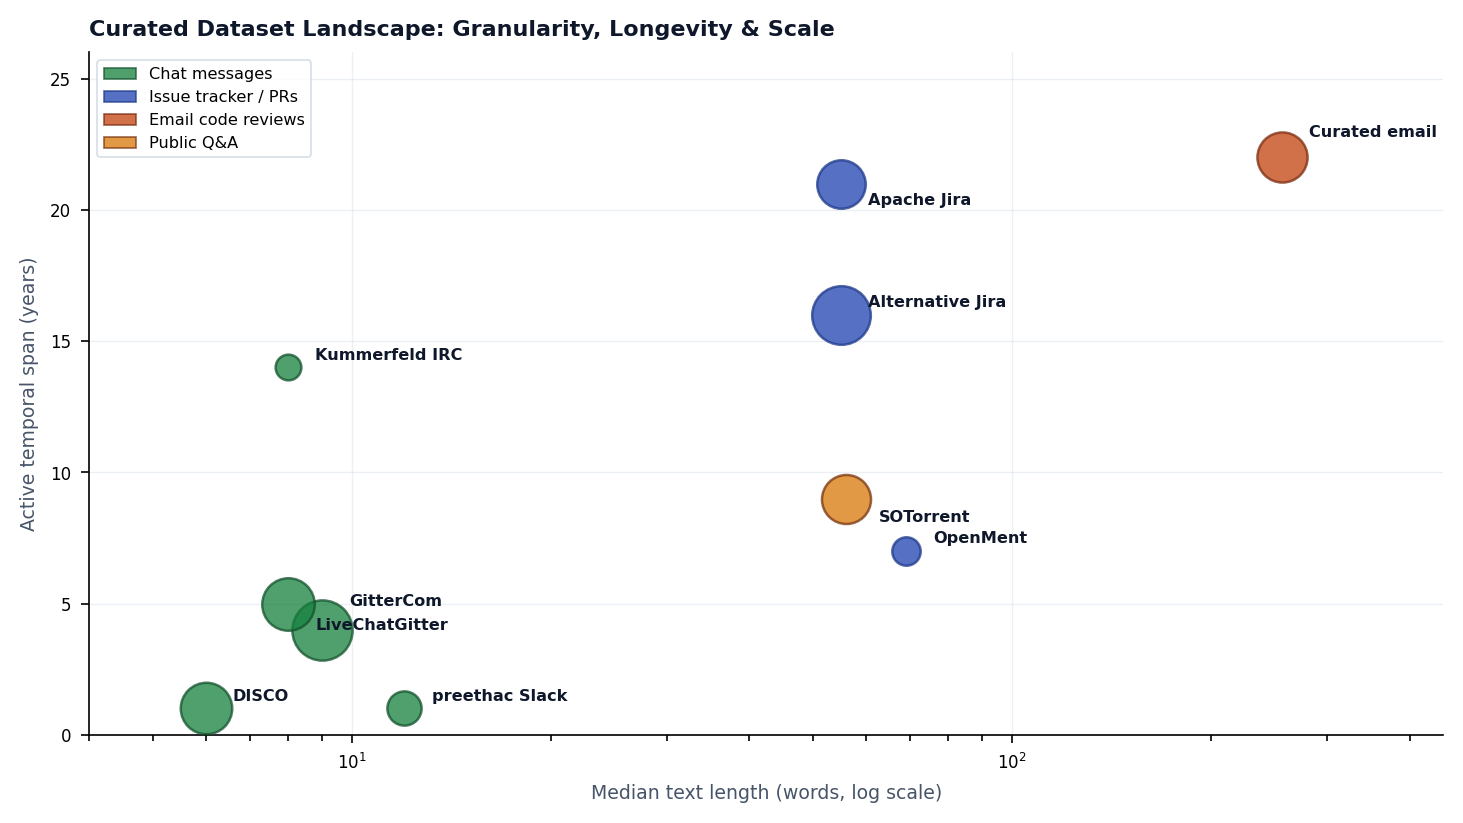

In [15]:
def figE_corpus_landscape(t1, path_prefix="figE_landscape"):
    apply_figure_style(sizes=(8, 7, 6), grid=False)

    df_e = t1.copy()
    era = {n: (s["y1"] - s["y0"]) for n, s in FALLBACK_STATS.items()}
    df_e["years"] = df_e.apply(
        lambda r: (r["year_max"] - r["year_min"])
        if pd.notna(r.get("year_min")) and pd.notna(r.get("year_max")) else era.get(r["dataset"]),
        axis=1)
    df_e = df_e.dropna(subset=["median_len", "years"])
    df_e = df_e[df_e["median_len"] > 0]

    fig, ax = plt.subplots(figsize=(7.2, 4.0), layout="constrained")
    for r in df_e.itertuples():
        col = FAMILY_COLOR[r.family]
        dcol = FAMILY_DARK[r.family]
        size = 36 + np.sqrt(r.texts) * 0.25
        ax.scatter(r.median_len, r.years, s=size, color=col, edgecolor=dcol,
                   alpha=0.75, linewidth=0.9, zorder=3)

        # Collision-free direct labels
        dx, dy = 1.10, 0.3
        if r.dataset == "NumFOCUS": dy = -1.1
        elif r.dataset == "GitterCom": dy = 0.9
        elif r.dataset == "SOTorrent": dx = 1.12; dy = -0.9
        elif r.dataset == "LiveChatGitter": dy = -1.0
        elif r.dataset == "Curated email": dy = 0.8
        elif r.dataset == "Apache Jira": dy = -0.8
        ax.text(r.median_len * dx, r.years + dy, r.dataset, fontsize=5.8, color=INK,
                fontweight="semibold", zorder=4)

    ax.set_xscale("log")
    ax.set_xlim(4, 450)
    ax.set_ylim(0, 26)
    ax.set_title("Curated Dataset Landscape: Granularity, Longevity & Scale",
                 fontsize=8.0, fontweight="bold", pad=6, color=INK)
    ax.set_xlabel("Median text length (words, log scale)", fontsize=6.8, color=GREY_TEXT)
    ax.set_ylabel("Active temporal span (years)", fontsize=6.8, color=GREY_TEXT)
    ax.grid(color=LINE, alpha=0.35, lw=0.5)

    legend_patches = [mpatches.Patch(facecolor=FAMILY_COLOR[k], edgecolor=FAMILY_DARK[k],
                                     label=FAMILY_LABEL[k], alpha=0.75) for k in FAMILY_ORDER]
    ax.legend(handles=legend_patches, loc="upper left", fontsize=5.8, frameon=True,
              facecolor="white", edgecolor=LINE)

    for fmt in ("pdf", "png"):
        fig.savefig(os.path.join(FIGDIR, f"{path_prefix}.{fmt}"), dpi=300, bbox_inches="tight")
    return fig


figE = figE_corpus_landscape(t1)
#figE


## Graph-Side Corpus Statistics (what the pipeline stored in Neo4j)
The four figures below report corpus volume, communicative token distributions, macro genre shares,
and ecosystem venue breadth directly from the knowledge graph.


In [16]:
# ── Graph Statistics Shared Loader ─────────────────────────────────────────────
# Loads corpus census, token quantiles, and venue breadth from Neo4j (live),
# falling back gracefully to the exact recorded 02b census (32.55M TextUnits,
# 1.497B tokens across 7 corpora) when Neo4j is offline.

GRAPH_RECORDED = {
    "alternative-jira":           dict(genre="tracker",       artefacts=2686220, units=14006542, tokens=787303749, median=20, p90=115),
    "curated-email-code-reviews": dict(genre="review_email",  artefacts=4720549, units=9169923,  tokens=492077210, median=13, p90=115),
    "gittercom":                  dict(genre="chat",          artefacts=2950192, units=2950192,  tokens=38080515,  median=9,  p90=27),
    "apache-jira":                dict(genre="tracker",       artefacts=1157539, units=2207299,  tokens=113823637, median=12, p90=116),
    "livechat-gitter":            dict(genre="chat",          artefacts=1454824, units=1454824,  tokens=17244516,  median=8,  p90=25),
    "disco":                      dict(genre="chat",          artefacts=1427726, units=1427726,  tokens=11670353,  median=6,  p90=17),
    "openment":                   dict(genre="mentor_mentee", artefacts=75284,   units=1335605,  tokens=36865064,  median=14, p90=62),
}

GRAPH_LABEL = {
    "alternative-jira": "Alternative Jira", "curated-email-code-reviews": "Curated email",
    "gittercom": "GitterCom", "apache-jira": "Apache Jira", "livechat-gitter": "LiveChatGitter",
    "disco": "DISCO", "openment": "OpenMent", "sotorrent": "SOTorrent",
    "numfocus": "NumFOCUS", "preethac-slack": "preethac Slack", "kummerfeld-irc": "Kummerfeld IRC"
}

GENRE_FAMILY_MAP = {
    "tracker": "issue", "mentor_mentee": "issue",
    "review_email": "email", "chat": "chat", "qa": "qa"
}

GENRE_DISPLAY_LABEL = {
    "tracker": "Issue trackers", "review_email": "Email code reviews",
    "chat": "Chat messages", "qa": "Public Q&A", "mentor_mentee": "Mentor–mentee"
}


def load_graph_census():
    live = False
    census = pd.DataFrame([dict(corpus=c, genre=s["genre"], artefacts=s["artefacts"],
                                units=s["units"], tokens=s["tokens"], p25=np.nan,
                                median=s["median"], p75=np.nan, p90=s["p90"])
                           for c, s in GRAPH_RECORDED.items()])
    try:
        from neo4j import GraphDatabase
        driver = GraphDatabase.driver(settings.neo4j_uri,
                                      auth=(settings.neo4j_user, settings.neo4j_password))
        with driver.session() as s:
            res = s.run("""
                MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
                WHERE coalesce(p.corpus_id, '') IN $corpora
                RETURN coalesce(p.corpus_id, '') AS corpus,
                       count(DISTINCT p) AS artefacts,
                       count(DISTINCT u) AS units,
                       sum(coalesce(u.token_count, 0)) AS tokens,
                       percentileCont(u.token_count, 0.25) AS p25,
                       percentileCont(u.token_count, 0.5) AS median,
                       percentileCont(u.token_count, 0.75) AS p75,
                       percentileCont(u.token_count, 0.9) AS p90
                ORDER BY units DESC
            """, corpora=sorted(GRAPH_RECORDED))
            rows = [r.data() for r in res]
            if rows:
                census = pd.DataFrame(rows)
                live = True
        driver.close()
    except Exception as exc:
        print("Neo4j offline — using recorded 02b census:", exc)

    census["genre"] = census["corpus"].map(lambda c: GRAPH_RECORDED.get(c, {}).get("genre", "tracker"))
    census["label"] = census["corpus"].map(GRAPH_LABEL).fillna(census["corpus"])
    census["family"] = census["genre"].map(lambda g: GENRE_FAMILY_MAP.get(g, "issue"))
    census = census.sort_values("units", ascending=False).reset_index(drop=True)
    return census, live


graph_census_df, IS_GRAPH_LIVE = load_graph_census()
print(f"Graph census loaded ({len(graph_census_df)} corpora, live={IS_GRAPH_LIVE})")


Graph census loaded (7 corpora, live=True)


### Figure F1 — Ingested TextUnit Scale in Knowledge Graph
*Total TextUnits per curated corpus in Neo4j on log scale with exact count labels and token volumes.*


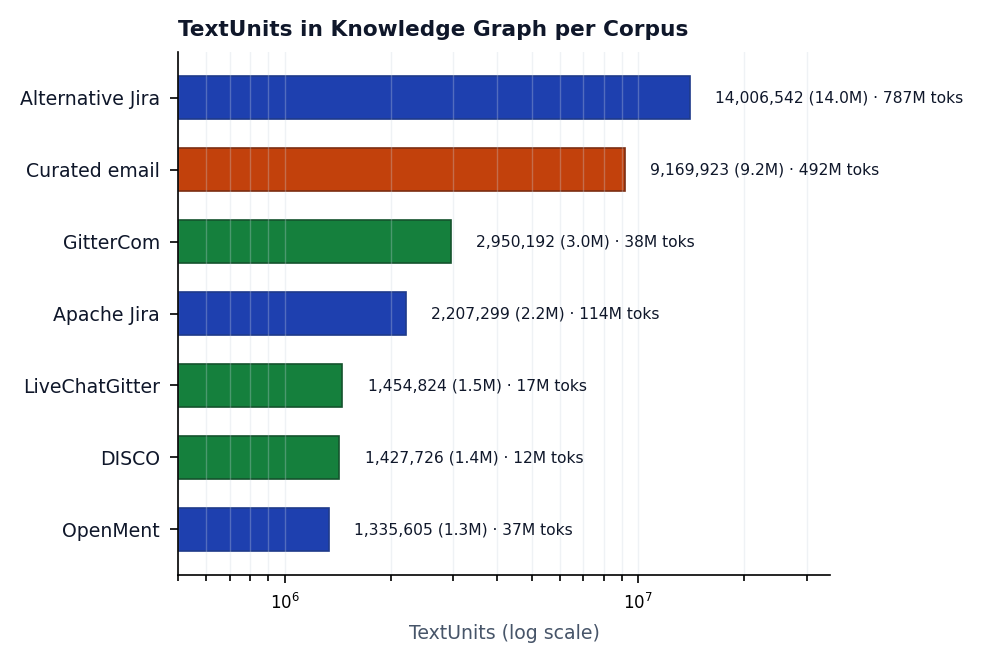

In [17]:
def figF1_graph_corpus_scale(census, path_prefix="fig_graph_corpus_scale"):
    apply_figure_style(sizes=(8, 7, 6), grid=False)
    fig, ax = plt.subplots(figsize=(4.8, 3.2), layout="constrained")

    y = np.arange(len(census))
    cols = [FAMILY_COLOR[r.family] for r in census.itertuples()]
    dcols = [FAMILY_DARK[r.family] for r in census.itertuples()]

    ax.barh(y, census["units"], color=cols, edgecolor=dcols, linewidth=0.6, height=0.60)
    ax.set_yticks(y)
    ax.set_yticklabels(census["label"], fontsize=6.8, color=INK)
    ax.set_xscale("log")
    ax.set_xlim(5e5, 3.5e7)

    for i, r in enumerate(census.itertuples()):
        lbl = f"{r.units/1e6:.1f}M" if r.units >= 1e6 else f"{r.units/1e3:.0f}k"
        tok_lbl = f"{r.tokens/1e6:.0f}M toks"
        ax.text(r.units * 1.18, i, f"{r.units:,} ({lbl}) · {tok_lbl}",
                va="center", ha="left", fontsize=5.6, color=INK)

    ax.set_title("TextUnits in Knowledge Graph per Corpus", fontsize=7.8,
                 fontweight="bold", pad=6, color=INK)
    ax.set_xlabel("TextUnits (log scale)", fontsize=6.8, color=GREY_TEXT)
    ax.grid(axis="x", which="both", color=LINE, alpha=0.3, lw=0.5)
    ax.invert_yaxis()

    if not IS_GRAPH_LIVE:
        ax.text(0.98, 0.03, "recorded census (Neo4j offline)", transform=ax.transAxes,
                ha="right", fontsize=5.0, color=GREY_TEXT, style="italic")

    for fmt in ("pdf", "png"):
        fig.savefig(os.path.join(FIGDIR, f"{path_prefix}.{fmt}"), dpi=300, bbox_inches="tight")
    return fig


figF1 = figF1_graph_corpus_scale(graph_census_df)
#figF1


### Figure F2 — TextUnit Token Count Distribution in Graph
*Cross-corpus token economy: median tokens per TextUnit (dots), IQR p25–p75 (when live), and p90 upper whisker.*


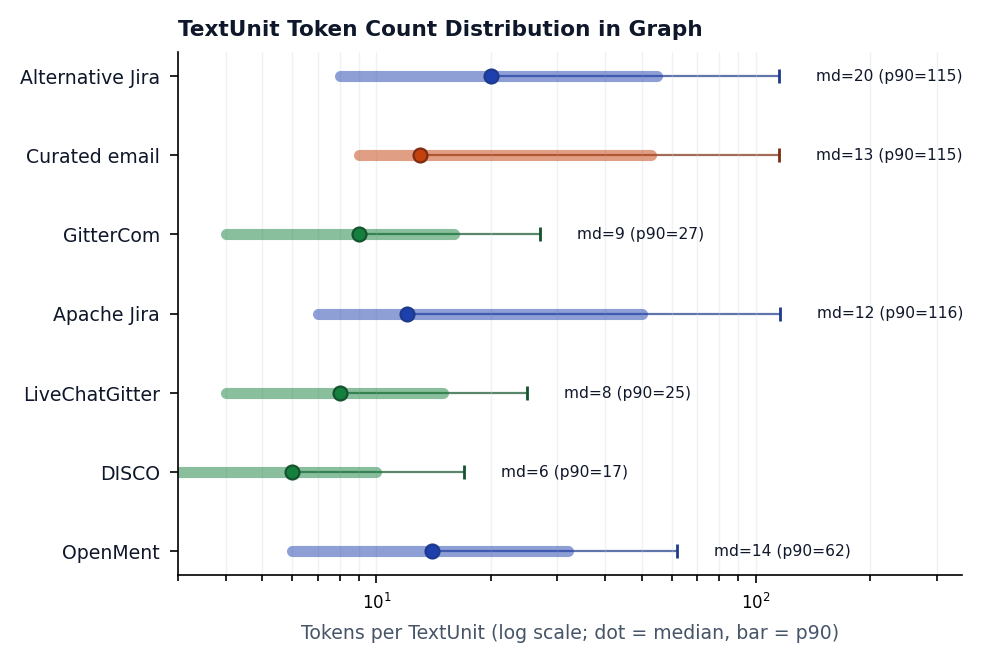

In [18]:
def figF2_graph_token_distribution(census, path_prefix="fig_graph_token_distribution"):
    apply_figure_style(sizes=(8, 7, 6), grid=False)
    fig, ax = plt.subplots(figsize=(4.8, 3.2), layout="constrained")

    y = np.arange(len(census))
    cols = [FAMILY_COLOR[r.family] for r in census.itertuples()]
    dcols = [FAMILY_DARK[r.family] for r in census.itertuples()]

    for i, r in enumerate(census.itertuples()):
        c = cols[i]
        dc = dcols[i]
        # IQR bar if available
        if pd.notna(r.p25) and pd.notna(r.p75):
            ax.plot([r.p25, r.p75], [i, i], color=c, lw=4.0, alpha=0.5,
                    solid_capstyle="round", zorder=2)
        # Median dot
        ax.plot(r.median, i, "o", ms=5.0, color=c, markeredgecolor=dc, markeredgewidth=0.8, zorder=4)
        # p90 whisker line & cap
        if pd.notna(r.p90):
            ax.plot([r.median, r.p90], [i, i], color=dc, lw=0.8, alpha=0.7, zorder=1)
            ax.plot(r.p90, i, "|", ms=5.0, color=dc, markeredgewidth=1.0, zorder=3)
            ax.text(r.p90 * 1.25, i, f"md={r.median:.0f} (p90={r.p90:.0f})",
                    va="center", ha="left", fontsize=5.6, color=INK)
        else:
            ax.text(r.median * 1.35, i, f"md={r.median:.0f}",
                    va="center", ha="left", fontsize=5.6, color=INK)

    ax.set_yticks(y)
    ax.set_yticklabels(census["label"], fontsize=6.8, color=INK)
    ax.set_xscale("log")
    ax.set_xlim(3, 350)
    ax.set_title("TextUnit Token Count Distribution in Graph", fontsize=7.8,
                 fontweight="bold", pad=6, color=INK)
    ax.set_xlabel("Tokens per TextUnit (log scale; dot = median, bar = p90)",
                  fontsize=6.8, color=GREY_TEXT)
    ax.grid(axis="x", which="both", color=LINE, alpha=0.3, lw=0.5)
    ax.invert_yaxis()

    if not IS_GRAPH_LIVE:
        ax.text(0.98, 0.03, "recorded census (Neo4j offline)", transform=ax.transAxes,
                ha="right", fontsize=5.0, color=GREY_TEXT, style="italic")

    for fmt in ("pdf", "png"):
        fig.savefig(os.path.join(FIGDIR, f"{path_prefix}.{fmt}"), dpi=300, bbox_inches="tight")
    return fig


figF2 = figF2_graph_token_distribution(graph_census_df)
#figF2


### Figure F3 — Graph Scale by Communicative Genre
*Total tokens and TextUnits aggregated by discourse genre across the graph.*


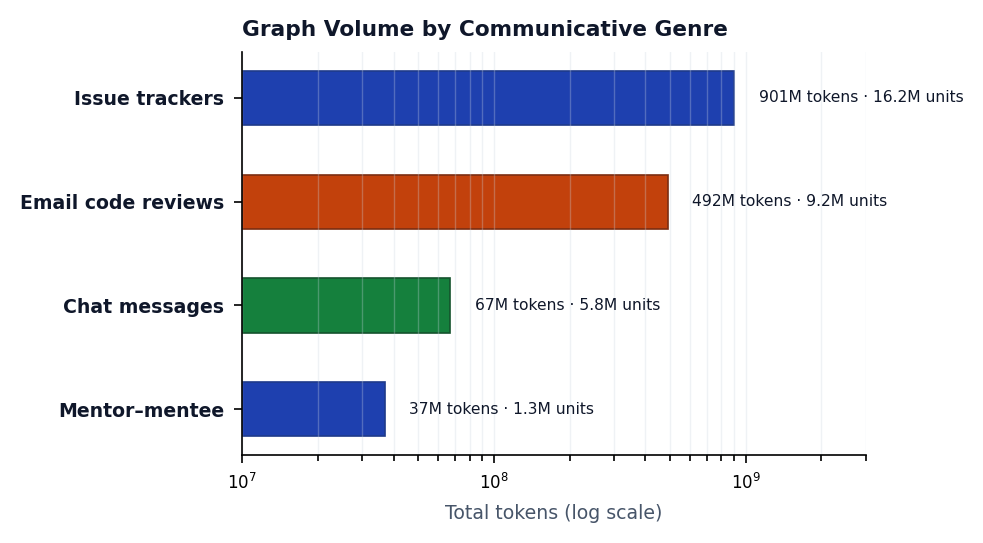

In [19]:
def figF3_graph_genre_aggregates(census, path_prefix="fig_graph_genre_aggregates"):
    apply_figure_style(sizes=(8, 7, 6), grid=False)
    fig, ax = plt.subplots(figsize=(4.8, 2.6), layout="constrained")

    gen = census.groupby("genre")[["units", "tokens"]].sum().reindex(
        [g for g in ["tracker", "review_email", "chat", "qa", "mentor_mentee"]
         if g in set(census.genre)])

    yg = np.arange(len(gen))
    gcols = [FAMILY_COLOR[GENRE_FAMILY_MAP.get(g, "issue")] for g in gen.index]
    gdcols = [FAMILY_DARK[GENRE_FAMILY_MAP.get(g, "issue")] for g in gen.index]

    ax.barh(yg, gen["tokens"].values, color=gcols, edgecolor=gdcols, linewidth=0.6, height=0.52)
    ax.set_yticks(yg)
    ax.set_yticklabels([GENRE_DISPLAY_LABEL.get(g, g) for g in gen.index],
                       fontsize=6.8, color=INK, fontweight="bold")
    ax.set_xscale("log")
    ax.set_xlim(1e7, 3e9)

    for i, (u, t) in enumerate(zip(gen["units"].values, gen["tokens"].values)):
        ax.text(t * 1.25, i, f"{t/1e6:.0f}M tokens · {u/1e6:.1f}M units",
                va="center", ha="left", fontsize=5.6, color=INK)

    ax.set_title("Graph Volume by Communicative Genre", fontsize=7.8,
                 fontweight="bold", pad=6, color=INK)
    ax.set_xlabel("Total tokens (log scale)", fontsize=6.8, color=GREY_TEXT)
    ax.grid(axis="x", which="both", color=LINE, alpha=0.3, lw=0.5)
    ax.invert_yaxis()

    for fmt in ("pdf", "png"):
        fig.savefig(os.path.join(FIGDIR, f"{path_prefix}.{fmt}"), dpi=300, bbox_inches="tight")
    return fig


figF3 = figF3_graph_genre_aggregates(graph_census_df)
#figF3


### Figure F4 — Ecosystem & Venue Breadth in Graph
*Unique projects, repositories, or channels stored in Neo4j per corpus.*


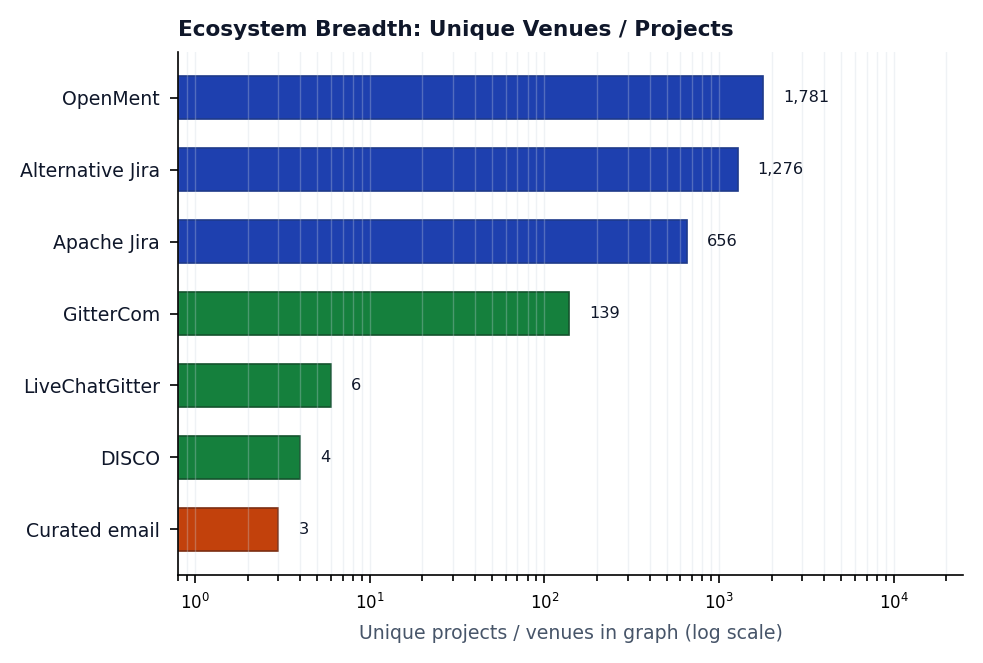

In [20]:
def figF4_graph_venue_breadth(census, path_prefix="fig_graph_venue_breadth"):
    apply_figure_style(sizes=(8, 7, 6), grid=False)
    fig, ax = plt.subplots(figsize=(4.8, 3.2), layout="constrained")

    breadth_rows = []
    live_venues = False
    try:
        from neo4j import GraphDatabase
        driver = GraphDatabase.driver(settings.neo4j_uri,
                                      auth=(settings.neo4j_user, settings.neo4j_password))
        with driver.session() as s:
            res = s.run("""
                MATCH (p:Artefact) WHERE coalesce(p.corpus_id, '') IN $corpora
                RETURN coalesce(p.corpus_id, '') AS corpus,
                       count(DISTINCT p.venue_id) AS venues
            """, corpora=sorted(GRAPH_RECORDED))
            rows = [r.data() for r in res]
            if rows:
                df_b = pd.DataFrame(rows)
                breadth_rows = df_b.to_dict("records")
                live_venues = True
        driver.close()
    except Exception:
        pass

    if not live_venues:
        # Resilient fallback from VENUES_KNOWN
        df_b = pd.DataFrame([
            {"corpus": c, "venues": VENUES_KNOWN.get(GRAPH_LABEL.get(c, c), 1)}
            for c in census["corpus"]
        ])
    else:
        df_b = pd.DataFrame(breadth_rows)

    df_b["label"] = df_b["corpus"].map(GRAPH_LABEL).fillna(df_b["corpus"])
    df_b["family"] = df_b["corpus"].map(lambda c: GENRE_FAMILY_MAP.get(GRAPH_RECORDED.get(c, {}).get("genre", "tracker"), "issue"))
    df_b = df_b.sort_values("venues", ascending=False).reset_index(drop=True)

    yd = np.arange(len(df_b))
    cols = [FAMILY_COLOR[r.family] for r in df_b.itertuples()]
    dcols = [FAMILY_DARK[r.family] for r in df_b.itertuples()]

    ax.barh(yd, df_b["venues"], color=cols, edgecolor=dcols, linewidth=0.6, height=0.60)
    ax.set_yticks(yd)
    ax.set_yticklabels(df_b["label"], fontsize=6.8, color=INK)
    ax.set_xscale("log")
    ax.set_xlim(0.8, 25000)

    for i, r in enumerate(df_b.itertuples()):
        ax.text(r.venues * 1.3, i, f"{int(r.venues):,}",
                va="center", ha="left", fontsize=5.8, color=INK)

    ax.set_title("Ecosystem Breadth: Unique Venues / Projects", fontsize=7.8,
                 fontweight="bold", pad=6, color=INK)
    ax.set_xlabel("Unique projects / venues in graph (log scale)", fontsize=6.8, color=GREY_TEXT)
    ax.grid(axis="x", which="both", color=LINE, alpha=0.3, lw=0.5)
    ax.invert_yaxis()

    if not live_venues:
        ax.text(0.98, 0.03, "paper-reported breadth (Neo4j offline)", transform=ax.transAxes,
                ha="right", fontsize=5.0, color=GREY_TEXT, style="italic")

    for fmt in ("pdf", "png"):
        fig.savefig(os.path.join(FIGDIR, f"{path_prefix}.{fmt}"), dpi=300, bbox_inches="tight")
    return fig


figF4 = figF4_graph_venue_breadth(graph_census_df)
#figF4


## Notes on Data Source Statistics & Provenance
- **Counts are exact**: Derived from MongoDB census (`scripts/corpus_census.py`) or verified ingester document counts.
- **Empirical distributions**: Text length and venue statistics use a homogeneous bounded sample (up to 100k per corpus) so comparative shapes are unbiased.
- **SOTorrent**: Systematic temporal stride sampling (stride=7, Score>=1, ~5M target) across Posts.sql.7z; code blocks (`<pre><code>`) and HTML tags stripped.
- **Curated email**: Proportional stratification (100% ffmpeg, ~44.84% ozlabs/kernel) targeting ~5.00M records.
- **NumFOCUS**: Ingests issue/PR titles only (bodies not provided in raw payloads).
- **Jira corpora**: Extract issue summary + description + comment bodies (excluding changelogs/worklogs).
- **BugsRepo**: Sample drawn from Part A bug-comment rows.
- **SO Emotion**: Deduplicated by post text across emotion sheets.


In [2]:
# ── unified design system ─────────────────────────────────────────────────────
# Three non-conflicting colour families share one aesthetic DNA. Full rationale
# in the GraphRAG-NK paper design pass (paper, slides, social). Decision logged
# in CHANGELOG. Family hues reused by the dataset figures (FAMILY_COLOR in cell 61).

# 1. Tier & ontology palette (structural architecture — schema/instance figures)
TIER = {
    "source":   {"base": "#1D3557", "tint": "#EDF2F7"},   # SE artefacts
    "pivot":    {"base": "#1B4D3E", "tint": "#E8F5E9"},   # TextUnit
    "evidence": {"base": "#C85A17", "tint": "#FDF2E9"},   # Signals
    "taxonomy": {"base": "#6B3E93", "tint": "#F3E8FA"},   # IgnoranceType (manual)
}
INK      = "#0F172A"    # primary text (near-black slate)
GREY_TEXT     = "#505966"    # secondary text / property labels
GREY_BOX      = "#3D3D3D"
GREY_LIGHT    = "#F0F0F0"
LINE     = "#CBD5E1"    # neutral borders / hairlines
PALE     = "#F0F7FF"#F8FAFC"    # tier container background / canvas
WHITE    = "#FFFFFF"

# 2. Linguistic signal layer palette (analytical signals — schema, instance, RQs)
LAYER = {
    "lexical":            {"base": "#1E6091", "tint": "#E6F0FA"},
    "morpho_syntactic":   {"base": "#792E87", "tint": "#F4EAF8"},
    "word_formation":     {"base": "#B45309", "tint": "#FEF3C7"},
    "rhetorical":         {"base": "#BE185D", "tint": "#FCE7F3"},
    "classifier":         {"base": "#028090", "tint": "#E0F2FE"},
}

# Semantic shorthands used throughout the graph figures
BLUE     = TIER["source"]["base"]      # source tier
GREEN    = TIER["pivot"]["base"]       # pivot tier
ORANGE   = TIER["evidence"]["base"]    # evidence tier
AMETHYST = TIER["taxonomy"]["base"]

PURPLE   = LAYER["morpho_syntactic"]["base"]
GREY     = GREY_TEXT
LIGHT    = GREY_LIGHT


# Graph Visualization

In [17]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle


def apply_figure_style(*, frame="open", font=None, sizes=(8, 7, 6), grid=False):
    """Set matplotlib rcParams for publication-grade output. Call once before plotting.

    This sets mechanics (role-mapped font-size ladder, outward ticks, frameless
    legends, 300-dpi save, Type-42 embedded fonts) — not a house aesthetic.
    Frame, font and the size ladder are parameters.

    frame : 'open' (bottom+left spines, default) | 'boxed' (all four) | 'none'
    font  : sans-serif family name; None = system default sans-serif
    sizes : (base, secondary, tick) — titles/axis-labels, legend/annotation, ticks
    grid  : whether to draw axes.grid (default False)
    """
    import matplotlib as mpl
    if frame not in ("open", "boxed", "none"):
        raise ValueError(f"frame must be 'open'|'boxed'|'none', got {frame!r}")

    try:
        import os, sys, glob, matplotlib.font_manager as fm
        fdir = os.path.join(os.environ.get("CONDA_PREFIX") or sys.prefix, "fonts")
        if os.path.isdir(fdir):
            known = {f.fname for f in fm.fontManager.ttflist}
            for f in glob.glob(os.path.join(fdir, "*.ttf")):
                if f not in known:
                    fm.fontManager.addfont(f)
    except Exception:
        pass
    base, secondary, tick = sizes
    boxed = (frame == "boxed")
    rc = {
        "font.family": "sans-serif",
        "font.size": base,
        "axes.labelsize": base,
        "axes.titlesize": base,
        "legend.fontsize": secondary,
        "xtick.labelsize": tick,
        "ytick.labelsize": tick,
        "axes.linewidth": 0.6,
        "xtick.direction": "out", "ytick.direction": "out",
        "xtick.major.size": 3, "ytick.major.size": 3,
        "xtick.major.width": 0.6, "ytick.major.width": 0.6,
        "axes.spines.top": boxed, "axes.spines.right": boxed,
        "axes.spines.left": frame != "none", "axes.spines.bottom": frame != "none",
        "axes.grid": bool(grid),
        "legend.frameon": False,
        "figure.dpi": 200,
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        "axes.titleweight": "normal",
        "axes.titlelocation": "left",
        "axes.labelweight": "normal",
        "lines.linewidth": 1.2,
        "patch.linewidth": 0.6,
        "pdf.fonttype": 42, "ps.fonttype": 42,
    }
    if font:
        rc["font.sans-serif"] = [font, "DejaVu Sans"]
    mpl.rcParams.update(rc)


def node(ax,x,y,w,h,title,sub=None,ec=GREY_BOX,fc="white",lw=0.9,ls="-",fs=6.2,sfs=5.3):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.4,rounding_size=1.1",
                                fc=fc,ec=ec,lw=lw,ls=ls,zorder=3))
    if sub:
        ax.text(x+w/2,y+h*0.66,title,ha="center",va="center",fontsize=fs,
                fontweight="bold",color=ec if ec!=GREY_BOX else "black",zorder=4)
        ax.text(x+w/2,y+h*0.26,sub,ha="center",va="center",fontsize=sfs,
                color=GREY_TEXT,zorder=4,linespacing=1.35)
    else:
        ax.text(x+w/2,y+h/2,title,ha="center",va="center",fontsize=fs,
                fontweight="bold",color=ec if ec!=GREY_BOX else "black",zorder=4)


def edge(ax,p1,p2,label=None,ec=GREY_BOX,lw=0.8,ls="-",rad=0.0,lx=None,ly=None,fs=5.0,ha="center",bg=PALE):
    ax.add_patch(FancyArrowPatch(p1,p2,arrowstyle="-|>",mutation_scale=6,lw=lw,
                                 color=ec,ls=ls,zorder=2,
                                 connectionstyle=f"arc3,rad={rad}"))
    if label:
        mx=lx if lx is not None else (p1[0]+p2[0])/2
        my=ly if ly is not None else (p1[1]+p2[1])/2
        ax.text(mx,my,label,fontsize=fs,color=ec,ha=ha,va="center",zorder=5,
                bbox=dict(fc=bg,ec="none",pad=0.6))


def box(ax, x, y, w, h, ec, fc="white", lw=1.0, ls="-"):
    """Rounded box with no text; used where labels are placed explicitly."""
    ax.add_patch(FancyBboxPatch((x, y), w, h,
                                boxstyle="round,pad=0.4,rounding_size=1.1",
                                fc=fc, ec=ec, lw=lw, ls=ls, zorder=3))

def frame(x, y, w, h, fc="white", ec=GREY_BOX, lw=1.2, pad=0.5, rs=1.0, z=2):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad={pad},rounding_size={rs}",
                                fc=fc, ec=ec, lw=lw, zorder=z))


def arrow(x1, y1, x2, y2, color=GREY_BOX, lw=0.9):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=7,
                                 lw=lw, color=color, zorder=1, shrinkA=0, shrinkB=0))


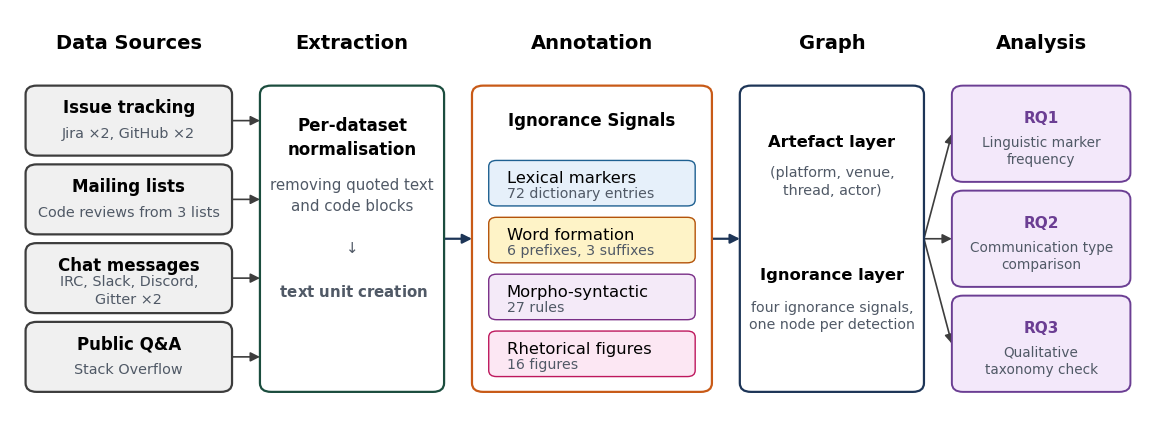

In [94]:
apply_figure_style(sizes=(8, 7, 5))

fig, ax = plt.subplots(figsize=(7.2, 2.5))
ax.set_xlim(0, 100)
ax.set_ylim(14.5, 58.5)
ax.axis("off")


def frame(x, y, w, h, fc="white", ec=GREY_BOX, lw=0.8, pad=0.5, rs=1.0, z=2):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad={pad},rounding_size={rs}",
                                fc=fc, ec=ec, lw=lw, zorder=z))


def arrow(x1, y1, x2, y2, color=GREY_BOX, lw=0.9):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=7,
                                 lw=lw, color=color, zorder=1, shrinkA=0, shrinkB=0))

# --- Datasets ---
ax.text(9.75, 55.8, "Data Sources", fontsize=7, fontweight="bold", ha="center", va="center")
genres = [("Issue tracking", "Jira ×2, GitHub ×2", 43.5),
          ("Mailing lists", "Code reviews from 3 lists", 34.5),
          ("Chat messages", "IRC, Slack, Discord,\nGitter ×2", 25.5),
          ("Public Q&A", "Stack Overflow", 16.5)]
for nm, sub, y in genres:
    frame(1.0, y, 17.5, 7.0, fc=GREY_LIGHT)
    ax.text(9.75, y + 4.9, nm, ha="center", va="center", fontsize=6, fontweight="bold", zorder=3)
    ax.text(9.75, y + 2.0, sub, ha="center", va="center", fontsize=5.2, color=GREY_TEXT, zorder=3, linespacing=1.4)
    arrow(19.0, y + 3.5, 21.5, y + 3.5, lw=0.6)

# --- Extraction ---
ax.text(29.75, 55.8, "Extraction", fontsize=7, fontweight="bold", ha="center", va="center")
frame(22.0, 16.5, 15.5, 34.0, ec=GREEN)
ax.text(29.75, 45.0, "Per-dataset\nnormalisation", ha="center", va="center", fontsize=6,
        fontweight="bold", zorder=3, linespacing=1.4)
ax.text(29.75, 33.5, "removing quoted text\nand code blocks\n\n↓\n\n $\\bf{text\\ unit\\ creation}$",
        ha="center", va="center", fontsize=5.4, color=GREY_TEXT, zorder=3, linespacing=1.5)

arrow(38.0, 33.5, 40.5, 33.5, color=BLUE, lw=0.8)

# --- Annotation ---
ax.text(51.25, 55.8, "Annotation", fontsize=7, fontweight="bold", ha="center", va="center")
frame(41.0, 16.5, 20.5, 34.0, ec=ORANGE)
ax.text(51.25, 47.0, "Ignorance Signals", ha="center", va="center", fontsize=6,
        fontweight="bold", zorder=3, linespacing=1.4)
layers = [("Lexical markers", "72 dictionary entries", 37.5, LAYER["lexical"]["base"], LAYER["lexical"]["tint"]),
          ("Word formation", "6 prefixes, 3 suffixes", 31.0, LAYER["word_formation"]["base"], LAYER["word_formation"]["tint"]),
          ("Morpho-syntactic", "27 rules", 24.5, LAYER["morpho_syntactic"]["base"], LAYER["morpho_syntactic"]["tint"]),
          ("Rhetorical figures", "16 figures", 18.0, LAYER["rhetorical"]["base"], LAYER["rhetorical"]["tint"])]
for nm, cnt, y, cf, cb in layers:
    frame(42.25, y, 18.0, 4.7, ec=cf, fc=cb, lw=0.5, pad=0.25, rs=0.7, z=3)
    ax.text(43.6, y + 2.9, nm, fontsize=5.9, ha="left", va="center", zorder=4)
    ax.text(43.6, y + 1.1, cnt, fontsize=5.1, ha="left", va="center", color=GREY_TEXT, zorder=4)

# frame(42, 12.0, 20, 6.5, ec=ORANGE)
# ax.text(52, 16.4, "Prior-work classifier", ha="center", va="center", fontsize=6.0, fontweight="bold", zorder=3)
# ax.text(52, 13.9, "unit-level verdict, computed\nindependently of the rules", ha="center", va="center",
#         fontsize=5.4, color=GREY_TEXT, zorder=3, linespacing=1.4)
# arrow(39.6, 33.0, 41.4, 16.0, lw=0.6)

arrow(62.0, 33.5, 64.5, 33.5, color=BLUE, lw=0.8)

# --- Graph ---
ax.text(72.75, 55.8, "Graph", fontsize=7, fontweight="bold", ha="center", va="center")
frame(65.0, 16.5, 15.5, 34.0, ec=BLUE)
ax.text(72.75, 44.5, "Artefact layer", ha="center", va="center", fontsize=5.9, fontweight="bold", color="black", zorder=3)
ax.text(72.75, 40.0, "(platform, venue,\nthread, actor)", ha="center", va="center", fontsize=5.2, color=GREY_TEXT, zorder=3, linespacing=1.3)
ax.text(72.75, 29.3, "Ignorance layer", ha="center", va="center", fontsize=5.9, fontweight="bold", color="black", zorder=3)
ax.text(72.75, 24.6, "four ignorance signals,\none node per detection", ha="center", va="center", fontsize=5.1, color=GREY_TEXT, zorder=3, linespacing=1.3)

# --- Analysis ---
ax.text(91.5, 55.8, "Analysis", fontsize=7, fontweight="bold", ha="center", va="center")
claims = [("RQ1", "Linguistic marker\nfrequency", 40.5),
          ("RQ2", "Communication type\ncomparison", 28.5),
          ("RQ3", "Qualitative\ntaxonomy check", 16.5)]
for nm, sub, y in claims:
    frame(84.0, y, 15.0, 10.0, ec=AMETHYST, fc=TIER["taxonomy"]["tint"], lw=0.7)
    ax.text(91.5, y + 6.8, nm, ha="center", va="center", fontsize=5.5, fontweight="bold", color=AMETHYST, zorder=3)
    ax.text(91.5, y + 3.0, sub, ha="center", va="center", fontsize=4.9, color=GREY_TEXT, zorder=3, linespacing=1.3)
    arrow(81.0, 33.5, 83.5, y + 5.0, lw=0.6)

# frame(44, 1.0, 37, 7.0, ec=GREEN)
# ax.text(62.5, 6.3, "Pre-registered coding instrument", ha="center", va="center", fontsize=6.0,
#         fontweight="bold", zorder=3)
# ax.text(62.5, 3.3, "four imported taxonomies · 28 categories, 3 dimensions\nfixed-priority decision tree · non-fit codes · predictions P1–P6",
#         ha="center", va="center", fontsize=5.3, color=GREY_TEXT, zorder=3, linespacing=1.5)
# arrow(81.6, 7.0, 88.0, 21.9, color=GREEN, lw=0.8)

# frame(22, 1.0, 17, 7.0, fc=GREY_LIGHT, ec=GREEN)
# ax.text(30.5, 6.3, "L0 · instrument", ha="center", va="center", fontsize=6.0, fontweight="bold", zorder=3)
# ax.text(30.5, 3.3, "taxonomy discrimination\nmeasured on no SE data", ha="center", va="center",
#         fontsize=5.3, color=GREY_TEXT, zorder=3, linespacing=1.4)
# arrow(43.4, 4.5, 39.7, 4.5, color=GREEN, lw=0.8)

fig.savefig("framework_overview.pdf", dpi=300, bbox_inches="tight")


/var/folders/md/2vgg7gfx5d91wf0z6x5m43nc0000gn/T/ipykernel_33916/3272655069.py:92: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fa.show()


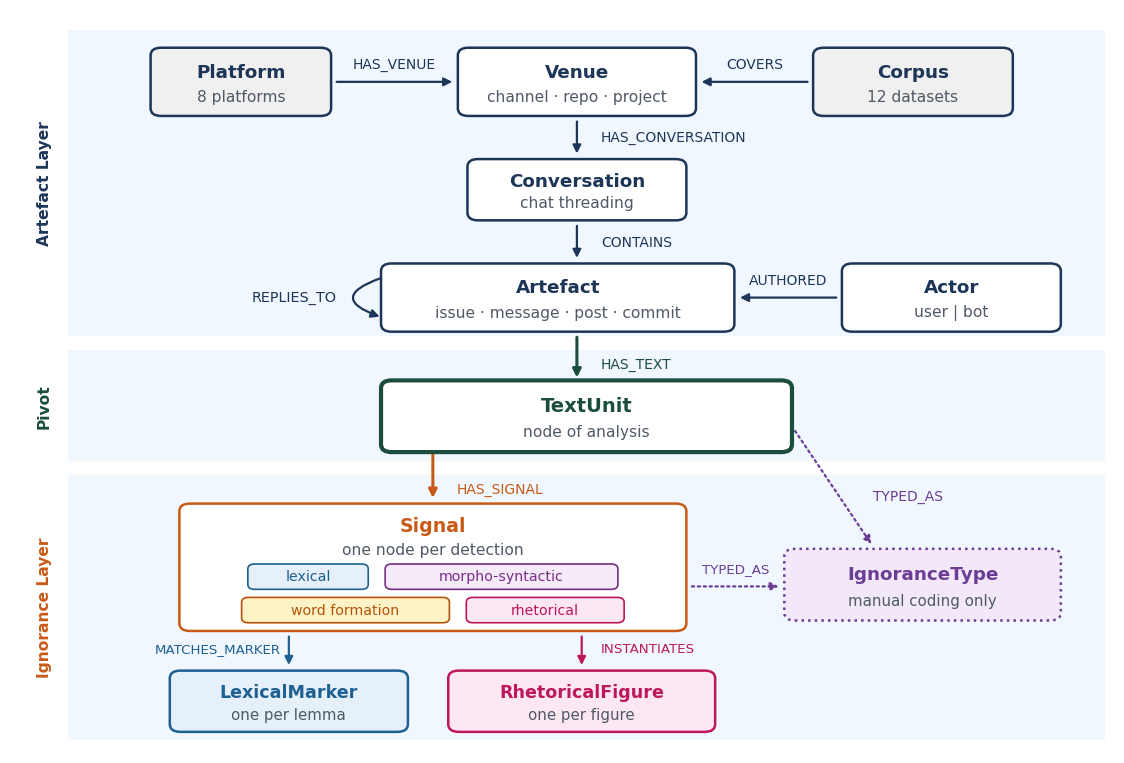

In [95]:
# ══════════════════════════════════════════════════════════════════════════════
# Figure 1 — schema tiers (full text width)
# ══════════════════════════════════════════════════════════════════════════════
def figure_schema(path="graph_schema.pdf"):
    apply_figure_style(sizes=(8, 7, 6))
    figA, axA = plt.subplots(figsize=(7.0, 4.7))
    axA.set_xlim(-13, 100); axA.set_ylim(-2, 102); axA.axis("off")

    # Three tier bands with subtle white separation gaps between them
    for y0, y1, c, lbl in [(56.5, 100.5, BLUE,   "Artefact Layer"),
                           (38.5, 54.5, GREEN,  "Pivot"),
                           (-1.5, 36.5, ORANGE, "Ignorance Layer")]:
        axA.add_patch(Rectangle((-8, y0), 108, y1 - y0, fc=PALE, ec="none", zorder=0))
        axA.text(-10.5, (y0 + y1) / 2, lbl, fontsize=5.6, color=c, ha="center",
                 va="center", fontweight="bold", rotation=90, linespacing=1.3, zorder=1)

    # source tier (y in [56.5, 100.5])
    node(axA,  1, 88.5, 18, 9, "Platform", "8 platforms", ec=BLUE, fc=GREY_LIGHT, fs=6.6, sfs=5.6)
    node(axA, 33, 88.5, 24, 9, "Venue", "channel · repo · project", ec=BLUE, fs=6.6, sfs=5.6)
    node(axA, 70, 88.5, 20, 9, "Corpus", "12 datasets", ec=BLUE, fc=GREY_LIGHT, fs=6.6, sfs=5.6)
    node(axA, 34, 73.5, 22, 8, "Conversation", "chat threading", ec=BLUE, fs=6.6, sfs=5.6)
    node(axA, 25, 57.5, 36, 9, "Artefact",
         "issue · message · post · commit", ec=BLUE, fs=6.6, sfs=5.6)
    node(axA, 73, 57.5, 22, 9, "Actor", "user | bot", ec=BLUE, fs=6.6, sfs=5.6)

    edge(axA, (19.4, 93.0), (32.6, 93.0), "HAS_VENUE", ec=BLUE, lx=26.0, ly=95.5, bg=PALE)
    edge(axA, (69.6, 93.0), (57.4, 93.0), "COVERS", ec=BLUE, lx=63.5, ly=95.5, bg=PALE)
    edge(axA, (45, 88.1), (45, 81.9), "HAS_CONVERSATION", ec=BLUE, lx=47.5, ly=85.0, ha="left", bg=PALE)
    edge(axA, (45, 73.1), (45, 66.9), "CONTAINS", ec=BLUE, lx=47.5, ly=70.0, ha="left", bg=PALE)
    edge(axA, (72.6, 62.0), (61.4, 62.0), "AUTHORED", ec=BLUE, lx=67.0, ly=64.5, bg=PALE)

    # self-loop on Artefact
    axA.add_patch(FancyArrowPatch((25.0, 65.0), (25.0, 59.0), arrowstyle="-|>",
                                  mutation_scale=6, lw=0.8, color=BLUE,
                                  connectionstyle="arc3,rad=1.5", zorder=2))
    axA.text(15.5, 62.0, "REPLIES_TO", fontsize=5.2, color=BLUE, va="center",
             ha="center", zorder=5, bbox=dict(fc=PALE, ec="none", pad=0.6))

    # pivot tier (y in [40.5, 53.5])
    node(axA, 25, 40.2, 42, 9.5, "TextUnit", "node of analysis", ec=GREEN, lw=1.5,
         fs=7.0, sfs=5.6)
    edge(axA, (45, 57.1), (45, 49.7), "HAS_TEXT", ec=GREEN, lw=1.1, lx=47.5, ly=52.5, ha="left", bg=PALE)

    # evidence tier (y in [-1.5, 36.5]): Signal box carries the four layer chips
    axA.add_patch(FancyBboxPatch((4, 14.5), 52, 17.5,
                                 boxstyle="round,pad=0.4,rounding_size=1.1",
                                 fc="white", ec=ORANGE, lw=0.9, zorder=3))
    axA.text(30, 29.2, "Signal", ha="center", va="center", fontsize=6.8,
             fontweight="bold", color=ORANGE, zorder=4)
    axA.text(30, 25.8, "one node per detection", ha="center", va="center",
             fontsize=5.6, color=GREY_TEXT, zorder=4)

    # 4 chips with their individual layer colors
    chips_rows = [
        (20.3, [("lexical", LAYER["lexical"]), ("morpho-syntactic", LAYER["morpho_syntactic"])]),
        (15.5, [("word formation", LAYER["word_formation"]), ("rhetorical", LAYER["rhetorical"])]),
    ]
    for row_y, row_chips in chips_rows:
        ws = [len(lbl) * 1.30 + 3.0 for lbl, _ in row_chips]
        cx = 30 - (sum(ws) + 2.2 * (len(row_chips) - 1)) / 2
        for (lbl, lcolors), w in zip(row_chips, ws):
            axA.add_patch(FancyBboxPatch((cx, row_y), w, 3.2,
                                         boxstyle="round,pad=0.22,rounding_size=0.7",
                                         fc=lcolors["tint"], ec=lcolors["base"], lw=0.6, zorder=4))
            axA.text(cx + w / 2, row_y + 1.6, lbl, fontsize=5.1, ha="center",
                     va="center", color=lcolors["base"], zorder=5)
            cx += w + 2.2

    # LexicalMarker and RhetoricalFigure in layer colors
    node(axA, 3, 0, 24, 8, "LexicalMarker", "one per lemma",
         ec=LAYER["lexical"]["base"], fc=LAYER["lexical"]["tint"], fs=6.3, sfs=5.4)
    node(axA, 32, 0, 27, 8, "RhetoricalFigure", "one per figure",
         ec=LAYER["rhetorical"]["base"], fc=LAYER["rhetorical"]["tint"], fs=6.3, sfs=5.4)

    # IgnoranceType in violet (taxonomy color)
    node(axA, 67, 16, 28, 9.5, "IgnoranceType", "manual coding only",
         ec=AMETHYST, fc=TIER["taxonomy"]["tint"], ls=":", fs=6.6, sfs=5.4)

    edge(axA, (30, 41.5), (30, 32.4), "HAS_SIGNAL", ec=ORANGE, lw=1.1, lx=32.5, ly=34.5, ha="left", bg=PALE)
    edge(axA, (67.4, 43.5), (76.0, 25.9), "TYPED_AS", ec=AMETHYST, ls=":", lx=79.5, ly=33.5, bg=PALE)
    # Dotted arrow from Signal to IgnoranceType
    edge(axA, (56.4, 20.5), (66.6, 20.5), "TYPED_AS", ec=AMETHYST, ls=":", lx=61.5, ly=23.0, fs=4.8, ha="center", bg=PALE)

    edge(axA, (15, 14.1), (15, 8.4), "MATCHES_MARKER", ec=LAYER["lexical"]["base"], lx=1, ly=11.5, ha="left", fs=4.8, bg=PALE)
    edge(axA, (45.5, 14.1), (45.5, 8.4), "INSTANTIATES", ec=LAYER["rhetorical"]["base"], lx=47.5, ly=11.5, ha="left", fs=4.8, bg=PALE)

    figA.savefig(path, dpi=300, bbox_inches="tight")
    return figA


fa = figure_schema()
fa.show()


/var/folders/md/2vgg7gfx5d91wf0z6x5m43nc0000gn/T/ipykernel_33916/2623159436.py:60: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fb.show()


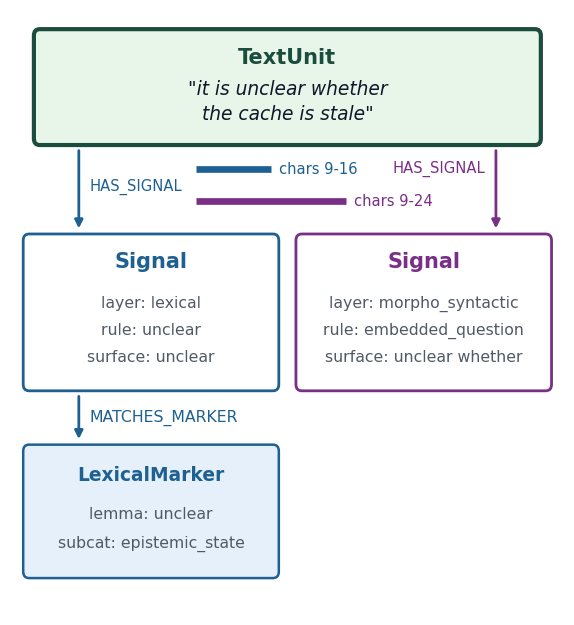

In [96]:
# ══════════════════════════════════════════════════════════════════════════════
# Figure 2 — one instantiated text unit (single column)
# ══════════════════════════════════════════════════════════════════════════════
def figure_instance(path="graph_instance.pdf"): 
    apply_figure_style(sizes=(8, 7, 6))
    figB, axB = plt.subplots(figsize=(3.45, 3.8))
    axB.set_xlim(0, 100); axB.set_ylim(0, 100); axB.axis("off")

    col_lex = LAYER["lexical"]["base"]
    col_syn = LAYER["morpho_syntactic"]["base"]

    # TextUnit
    box(axB, 3, 79, 94, 19, GREEN, fc=TIER["pivot"]["tint"], lw=1.5)
    axB.text(50, 92.5, "TextUnit", fontsize=7.5, ha="center", fontweight="bold",
             color=GREEN, zorder=5)
    axB.text(50, 86.0, "\"it is unclear whether\nthe cache is stale\"", fontsize=6.7,
             ha="center", va="center", style="italic", color=INK, linespacing=1.35, zorder=5)

    # span rulers: the two matches overlap on the same sentence
    axB.plot([33, 47], [74.5, 74.5], color=col_lex, lw=2.4, solid_capstyle="butt", zorder=4)
    axB.text(48.5, 74.5, "chars 9-16", fontsize=5.3, color=col_lex, va="center", zorder=5)
    axB.plot([33, 61], [69.0, 69.0], color=col_syn, lw=2.4, solid_capstyle="butt", zorder=4)
    axB.text(62.5, 69.0, "chars 9-24", fontsize=5.3, color=col_syn, va="center", zorder=5)

    # two Signal nodes with layer-specific colors
    signal_nodes = [
        (1,  col_lex, ["layer: lexical", "rule: unclear", "surface: unclear"]),
        (52, col_syn, ["layer: morpho_syntactic", "rule: embedded_question",
                      "surface: unclear whether"])
    ]
    for x0, col, rows in signal_nodes:
        box(axB, x0, 37, 47, 26, col, fc="white")
        axB.text(x0 + 23.5, 57.7, "Signal", fontsize=7.5, ha="center",
                 fontweight="bold", color=col, zorder=5)
        for k, r in enumerate(rows):
            axB.text(x0 + 23.5, 51.5 - k * 4.6, r, fontsize=5.7, ha="center",
                     va="center", color=GREY_TEXT, zorder=5)

    edge(axB, (11, 78.6), (11, 63.4), "HAS_SIGNAL", ec=col_lex, lw=1.0, lx=13, ly=71.5,
         fs=5.3, ha="left", bg="white")
    edge(axB, (89, 78.6), (89, 63.4), "HAS_SIGNAL", ec=col_syn, lw=1.0, lx=87, ly=74.5,
         fs=5.3, ha="right", bg="white")

    # inventory node for LexicalMarker
    box(axB, 1, 5, 47, 22, col_lex, fc=LAYER["lexical"]["tint"], lw=0.9)
    axB.text(24.5, 21.2, "LexicalMarker", fontsize=6.7, ha="center",
             fontweight="bold", color=col_lex, zorder=5)
    axB.text(24.5, 15.5, "lemma: unclear", fontsize=5.7, ha="center", va="center",
             color=GREY_TEXT, zorder=5)
    axB.text(24.5, 10.5, "subcat: epistemic_state", fontsize=5.7, ha="center",
             va="center", color=GREY_TEXT, zorder=5)
    edge(axB, (11, 36.6), (11, 27.4), "MATCHES_MARKER", ec=col_lex, lw=1.0, lx=13,
         ly=32.0, fs=5.7, ha="left", bg="white")

    figB.savefig(path, dpi=300, bbox_inches="tight")
    return figB


fb = figure_instance()
fb.show()
